# Mini-projet Data Mining — Détection automatique des crises d'absence (EEG)

**Pipeline :** Signal EEG → Exploration → Prétraitement → Segmentation → Extraction des features → Jeu de classification → Machine Learning (DT, RF, KNN, SVM) → Évaluation → Meilleur modèle → Détection temporelle → Début / Fin de chaque crise

Le notebook est fait pour **Google Colab** : la première cellule monte Google Drive et copie le dossier `DataMining` en local.

## 0. Installation, téléchargement des données depuis Google Drive

In [2]:
import os, sys, io, re, glob, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from scipy.io.matlab._mio5 import MatFile5Reader
from scipy.signal import butter, sosfiltfilt, medfilt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Cherche le dossier DataMining dans "Mon Drive"
    candidates = [Path("/content/drive/MyDrive/DataMining")] + \
                 [Path(p) for p in glob.glob("/content/drive/MyDrive/*/DataMining")] + \
                 [Path(p) for p in glob.glob("/content/drive/MyDrive/*/*/DataMining")]
    SRC_DIR = next((p for p in candidates if p.is_dir()), None)
    assert SRC_DIR is not None, "Dossier DataMining introuvable : ajuste SRC_DIR à la main."
    # Copie locale (lecture beaucoup plus rapide que depuis le Drive monté)
    DATA_DIR = Path("/content/DataMining")
    if not DATA_DIR.exists():
        shutil.copytree(SRC_DIR, DATA_DIR)
    OUT_DIR = SRC_DIR.parent / "DataMining_resultats"   # résultats sauvegardés sur le Drive, HORS du dossier du prof
else:
    DATA_DIR = Path(os.environ.get("DM_DATA", "DataMining"))
    OUT_DIR = Path(os.environ.get("DM_OUT", "resultats"))

OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*_0000d.mat"))
ANNOT_FILE = next(iter(sorted(DATA_DIR.glob("*nnotation*.xlsx"))), None)
print(f"{len(DATA_FILES)} enregistrements trouvés dans {DATA_DIR}")
print("Fichier d'annotations :", ANNOT_FILE)

Mounted at /content/drive
22 enregistrements trouvés dans /content/DataMining
Fichier d'annotations : /content/DataMining/Annotations MAJ.xlsx


## 1. Chargement des fichiers `.mat`

Les fichiers `_0000d.mat` contiennent un objet MATLAB **timetable** (`output_d`). `scipy.io.loadmat` ne sait pas décoder ce type d'objet directement : les données sont stockées dans la partie cachée du fichier (`__function_workspace__`). La fonction ci-dessous la décode.

Structure obtenue : une ligne de la timetable = **1 seconde**, chaque cellule contient les **N échantillons** de cette seconde pour un canal. On les met bout à bout pour reconstruire un signal continu.

In [9]:
def _read_timetable(path):
    # Décode l'objet timetable MATLAB stocké dans le sous-système du fichier .mat
    m = loadmat(path)
    fw = m["__function_workspace__"].tobytes()
    header = b"MATLAB 5.0 MAT-file".ljust(116, b" ") + b"\x00" * 8 + fw[:4]
    stream = io.BytesIO(header + fw[8:])
    reader = MatFile5Reader(stream, struct_as_record=False, squeeze_me=True)
    reader.initialize_read()
    stream.seek(128)
    hdr, _ = reader.read_var_header()
    subsystem = reader.read_var_array(hdr, process=True)
    opaque = np.atleast_1d(subsystem.MCOS)[0]
    # Le tableau des objets est le DERNIER champ de l'objet opaque :
    # 'arr' (anciennes versions de scipy, ex. Colab) ou '_ObjectMetadata' (versions récentes)
    objects = opaque[opaque.dtype.names[-1]] if opaque.dtype.names else opaque
    objects = np.atleast_1d(objects).ravel()
    tt = next((o for o in objects if hasattr(o, "_fieldnames") and "varNames" in o._fieldnames), None)
    if tt is None:
        raise ValueError(f"Timetable introuvable dans {Path(path).name}")
    n_rows = int(tt.numRows)
    # temps des lignes (en ms) : tableau float de longueur numRows
    row_times = next((np.asarray(o, float) for o in objects
                      if isinstance(o, np.ndarray) and o.dtype == float and o.size == n_rows), None)
    return tt, row_times


def load_eeg(path):
    # Retourne (DataFrame [Time + canaux], fréquence d'échantillonnage)
    tt, row_times = _read_timetable(path)
    names = [str(n) for n in np.atleast_1d(tt.varNames)]
    columns = {}
    for name, cells_ in zip(names, np.atleast_1d(tt.data)):
        columns[name] = np.concatenate([np.atleast_1d(c).astype(np.float32) for c in np.atleast_1d(cells_)])
    samples_per_row = np.atleast_1d(np.atleast_1d(tt.data)[0][0]).size
    row_dt = np.median(np.diff(row_times)) / 1000.0 if row_times is not None and row_times.size > 1 else 1.0
    fs = samples_per_row / row_dt
    df = pd.DataFrame(columns)
    df.insert(0, "Time", np.arange(len(df)) / fs)
    return df, fs


def recording_id(path):
    # '210914B_A_0000d.mat' -> '210914B-A' (format des annotations)
    parts = Path(path).stem.split("_")
    return f"{parts[0]}-{parts[1]}"


REC_IDS = [recording_id(f) for f in DATA_FILES]
print(REC_IDS)

['190304A-E', '191113A-D', '200625A-F', '210204B-C', '210208B-G', '210406A-F', '210427B-C', '210504B-C', '210914B-A', '210928B-B', '211027B-C', '211104B-D', '220106A-A', '220121B-D', '230102B-F', '230105B-H', '230210B-D', '230224B-B', '230406B-A', '230515B-G', '230519A-E', '230718A-A']


## 2. Chargement des annotations (utilisées dès la Question 2)

Les instants du fichier Excel sont des **heures** (fractions de jour Excel). La position d'une crise dans l'enregistrement est donc :
`début (s) = (DebCE − DebutTrace) × 86400`.

Contrôles appliqués : lignes dupliquées (même enregistrement annoté deux fois → on garde la première), crises de durée nulle/négative ou aberrante (> 120 s, ex. la 1ʳᵉ crise de `210504B-C` qui dure 6 h → erreur de saisie) ou en dehors de l'enregistrement.

In [10]:
MAX_SEIZURE_S = 120

def load_annotations(xlsx):
    a = pd.read_excel(xlsx)
    a = a.rename(columns={a.columns[0]: "ID"})
    a = a[a["ID"].notna() & a["DebutTrace"].notna()].copy()
    a["ID"] = a["ID"].astype(str).str.strip()
    dup = a[a["ID"].duplicated()]["ID"].tolist()
    if dup:
        print("Annotations dupliquées (1ʳᵉ ligne conservée) :", dup)
    a = a.drop_duplicates("ID", keep="first")

    start_cols = {int(re.search(r"(\d+)$", c).group(1)): c for c in a.columns if re.match(r"^Deb\w*CE\d+$", c)}
    end_cols = {int(re.search(r"(\d+)$", c).group(1)): c for c in a.columns if re.match(r"^FinCE\d+$", c)}
    rows = []
    for _, r in a.iterrows():
        t0 = r["DebutTrace"]
        for k in sorted(start_cols):
            s, e = r[start_cols[k]], r.get(end_cols.get(k))
            if pd.isna(s) or pd.isna(e):
                continue
            start = round((s - t0) * 86400, 2)
            end = round((e - t0) * 86400, 2)
            if start < 0:
                start, end = start + 86400, end + 86400   # passage de minuit
            rows.append({"ID": r["ID"], "Crise": k, "Début (s)": start, "Fin (s)": end,
                         "Durée (s)": round(end - start, 2)})
    seiz = pd.DataFrame(rows)
    bad = seiz[(seiz["Durée (s)"] <= 0) | (seiz["Durée (s)"] > MAX_SEIZURE_S)]
    if len(bad):
        print("Crises écartées (durée aberrante) :")
        display(bad)
    seiz = seiz.drop(bad.index).reset_index(drop=True)
    meta = a[["ID", "Sexe", "Age", "NombreCE", "TypeAbs"]].reset_index(drop=True)
    return seiz, meta


SEIZURES, META = load_annotations(ANNOT_FILE)

# On garde uniquement les crises qui tombent dans l'enregistrement
dur = {}
for f in DATA_FILES:
    try:
        tt, _ = _read_timetable(f)
        n_per_row = np.atleast_1d(np.atleast_1d(tt.data)[0][0]).size
        dur[recording_id(f)] = float(tt.numRows)  # 1 ligne = 1 s
    except (StopIteration, Exception) as error:
        print(f"Impossible de lire la timetable pour {f.name} (fichier ignoré ou corrompu) : {error}")

outside = SEIZURES[SEIZURES["ID"].map(dur).notna() & (SEIZURES["Début (s)"] >= SEIZURES["ID"].map(dur))]
if len(outside):
    print("Crises hors de l'enregistrement (écartées) :")
    display(outside)
SEIZURES = SEIZURES.drop(outside.index).reset_index(drop=True)

no_annot = sorted(set(REC_IDS) - set(SEIZURES["ID"]))
print("Enregistrements sans annotation (exclus de l'apprentissage) :", no_annot)

def seizure_table(rec):
    t = SEIZURES[SEIZURES["ID"] == rec].sort_values("Début (s)").reset_index(drop=True)
    t["Crise"] = np.arange(1, len(t) + 1)
    return t[["Crise", "Début (s)", "Fin (s)", "Durée (s)"]]

META

Annotations dupliquées (1ʳᵉ ligne conservée) : ['230406B-A', '230515B-G']
Crises écartées (durée aberrante) :


,ID,Crise,Début (s),Fin (s),Durée (s)
5,210504B-C,1,0.0,21608.0,21608.0


Enregistrements sans annotation (exclus de l'apprentissage) : ['200625A-F', '210204B-C', '210208B-G']


,ID,Sexe,Age,NombreCE,TypeAbs
0,190304A-E,M,17.0,1.0,NaN
1,191113A-D,F,25.0,2.0,NaN
2,210406A-F,F,8.0,1.0,NaN
3,210427B-C,M,11.0,1.0,NaN
4,210504B-C,M,11.0,12.0,NaN
5,210914B-A,F,8.0,6.0,atypiques
6,210928B-B,M,7.0,2.0,NaN
7,211027B-C,F,5.0,8.0,NaN
8,211104B-D,M,9.0,5.0,NaN
9,230406B-A,M,11.0,4.0,NaN


## Partie I — Compréhension et exploration des données

### Question 1

In [11]:
# Enregistrement étudié en détail dans les parties I à VI
PREFERRED = "230102B-F"
REC_DEMO = PREFERRED if PREFERRED in REC_IDS else REC_IDS[0]
FILE_DEMO = DATA_FILES[REC_IDS.index(REC_DEMO)]

eeg, FS = load_eeg(FILE_DEMO)
EEG_CHANNELS = [c for c in eeg.columns if c.startswith("EEG")]   # 19 électrodes (on exclut SLI et ECG)

print(f"Enregistrement           : {REC_DEMO}")
print(f"Nombre de lignes         : {len(eeg):,}")
print(f"Nombre de variables      : {eeg.shape[1]} (Time + {eeg.shape[1]-1} canaux, dont {len(EEG_CHANNELS)} EEG)")
print(f"Fréquence d'échantillon. : {FS:.0f} Hz")
print(f"Durée totale             : {len(eeg)/FS:.1f} s ({len(eeg)/FS/60:.1f} min)")
print(f"Valeurs manquantes       : {int(eeg.isna().sum().sum())}")
print("Canaux :", list(eeg.columns[1:]))
eeg.head(10)

Enregistrement           : 230102B-F
Nombre de lignes         : 313,600
Nombre de variables      : 22 (Time + 21 canaux, dont 19 EEG)
Fréquence d'échantillon. : 256 Hz
Durée totale             : 1225.0 s (20.4 min)
Valeurs manquantes       : 0
Canaux : ['EEGFp1', 'EEGFp2', 'EEGF7', 'EEGF3', 'EEGFz', 'EEGF4', 'EEGF8', 'EEGT4', 'EEGC4', 'EEGCz', 'EEGC3', 'EEGT3', 'EEGT5', 'EEGP3', 'EEGPz', 'EEGP4', 'EEGT6', 'EEGO2', 'EEGO1', 'SLI', 'ECG']


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,EEGCz,EEGC3,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.000000,519.155640,809.653687,631.202332,-19.420233,2631.396973,1.342412,818.961060,8.322957,407.108948,677.202332,-131.108948,358.961090,92.984436,678.813232,246.735413,181.941635,-165.116730,135.225677,329.428009,0.089494,3126.657471
1,0.003906,329.785980,591.287964,443.801544,-208.073929,2528.657471,-198.587555,594.509705,-169.591446,187.848251,479.420227,-311.708160,169.949417,-96.743187,488.727631,40.003891,-104.439690,-350.548645,-51.638134,152.945526,0.089494,3309.941650
2,0.007812,199.840469,466.354095,312.066162,-339.093384,2381.171143,-329.606995,466.712067,-299.000000,39.824902,351.264587,-440.579773,41.972763,-230.268478,358.424133,-91.552528,-242.976654,-476.914398,-178.361862,15.840466,0.089494,3449.910400
3,0.011719,298.642029,601.132324,412.299622,-237.785995,2620.657471,-219.529190,607.396912,-205.031128,161.178986,462.774323,-344.105072,146.322952,-128.424118,461.879364,24.252918,-48.237354,-373.817108,-75.085602,103.902725,0.089494,3377.778320
4,0.015625,497.856018,818.961060,617.957214,-32.486382,2880.369629,-9.038911,835.070068,-3.132296,401.739288,675.233459,-139.163422,353.949402,82.603111,670.937744,242.797668,234.206223,-166.190659,134.330734,310.276276,0.089494,3196.642090
5,0.019531,527.389099,827.731506,647.848267,-1.700389,2940.509766,13.334630,839.007812,28.548637,433.778198,699.217896,-101.396889,384.198456,115.357979,696.175110,260.338531,220.424118,-137.552536,164.937744,352.696503,0.089494,3118.424072
6,0.023438,349.832672,620.284058,466.354095,-178.719849,2819.513672,-178.719849,622.073914,-143.101166,224.003891,510.922180,-271.972748,202.883270,-69.178986,508.953308,55.396889,-61.303501,-316.898834,-12.439689,179.972763,0.089494,3220.984375
7,0.027344,198.408554,469.575867,316.003906,-327.101166,2647.147949,-327.996094,472.260712,-283.964966,58.081711,366.299622,-418.564209,55.754864,-221.140076,362.719849,-96.385216,-229.015564,-460.089508,-151.871597,28.548637,0.089494,3318.175049
8,0.031250,273.404663,575.357971,395.295715,-246.556427,2700.128418,-236.354080,587.887146,-209.684830,156.704285,460.089508,-342.673157,139.163422,-139.700394,447.918274,1.879377,-61.124512,-380.439697,-63.988327,101.038910,0.089494,3201.474609
9,0.035156,477.451355,799.809326,601.848267,-39.108948,2886.097168,-22.821012,815.918274,-15.303502,394.042816,673.622559,-143.817123,342.494171,61.840466,651.964966,220.782104,224.182877,-179.077820,140.058365,298.642029,0.089494,2955.723633


In [12]:
# Vue d'ensemble de tous les enregistrements
summary = []
for f in DATA_FILES:
    d, fs = load_eeg(f)
    summary.append({"Enregistrement": recording_id(f), "Lignes": len(d), "Canaux": d.shape[1] - 1,
                    "Fs (Hz)": fs, "Durée (s)": round(len(d) / fs, 1), "Manquantes": int(d.isna().sum().sum())})
    del d
summary = pd.DataFrame(summary)
summary

,Enregistrement,Lignes,Canaux,Fs (Hz),Durée (s),Manquantes
0,190304A-E,403200,23,256.0,1575.0,0
1,191113A-D,463360,23,256.0,1810.0,0
2,200625A-F,457728,12,256.0,1788.0,0
3,210204B-C,314112,21,256.0,1227.0,0
4,210208B-G,307200,21,256.0,1200.0,0
5,210406A-F,372224,23,256.0,1454.0,0
6,210427B-C,318976,21,256.0,1246.0,0
7,210504B-C,798976,21,256.0,3121.0,0
8,210914B-A,308480,21,256.0,1205.0,0
9,210928B-B,344064,21,256.0,1344.0,0


In [13]:
eeg[EEG_CHANNELS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
EEGFp1,313600.0,253.29,218.03,-2781.03,132.90,250.14,369.70,5823.30
EEGFp2,313600.0,513.78,215.42,-2508.79,380.08,512.53,647.49,5815.42
EEGF7,313600.0,361.76,217.36,-2737.36,244.05,362.72,481.93,5818.82
EEGF3,313600.0,-214.44,217.34,-3344.13,-333.90,-214.34,-94.77,5862.67
EEGFz,313600.0,46.85,1449.78,-5865.00,49.49,72.22,95.31,5865.00
EEGF4,313600.0,-211.87,219.57,-3339.83,-334.44,-211.83,-88.51,5858.91
EEGF8,313600.0,521.82,222.43,-2560.70,387.42,521.66,658.05,5825.44
EEGT4,313600.0,-198.92,220.45,-3325.33,-314.57,-199.30,-83.32,5865.00
EEGC4,313600.0,173.06,235.69,-3251.95,37.14,172.46,309.56,5843.52
EEGCz,313600.0,420.53,282.35,-2698.70,292.38,414.63,538.67,5811.84


### Question 2 — Représentation graphique du signal

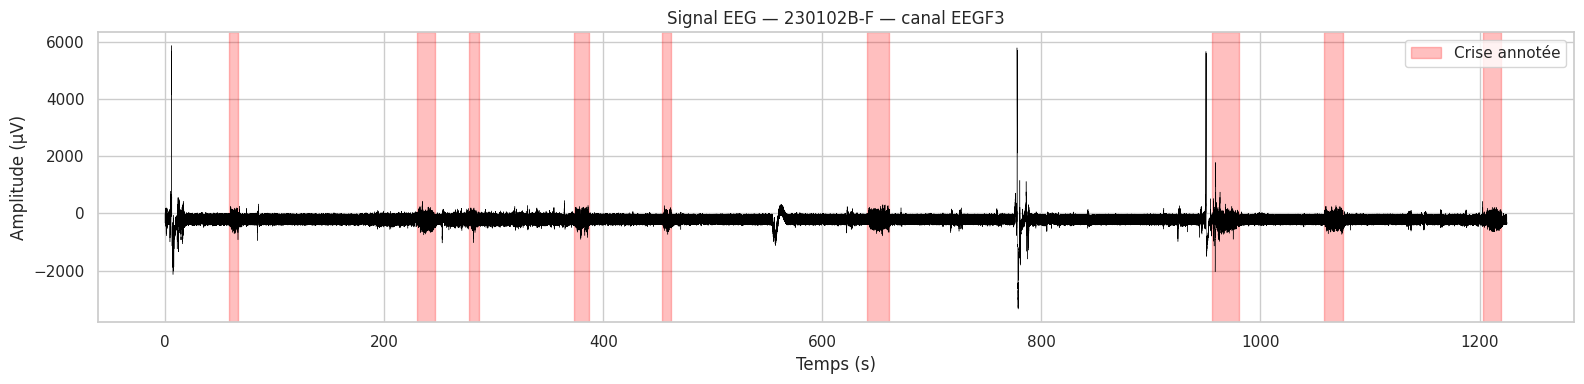

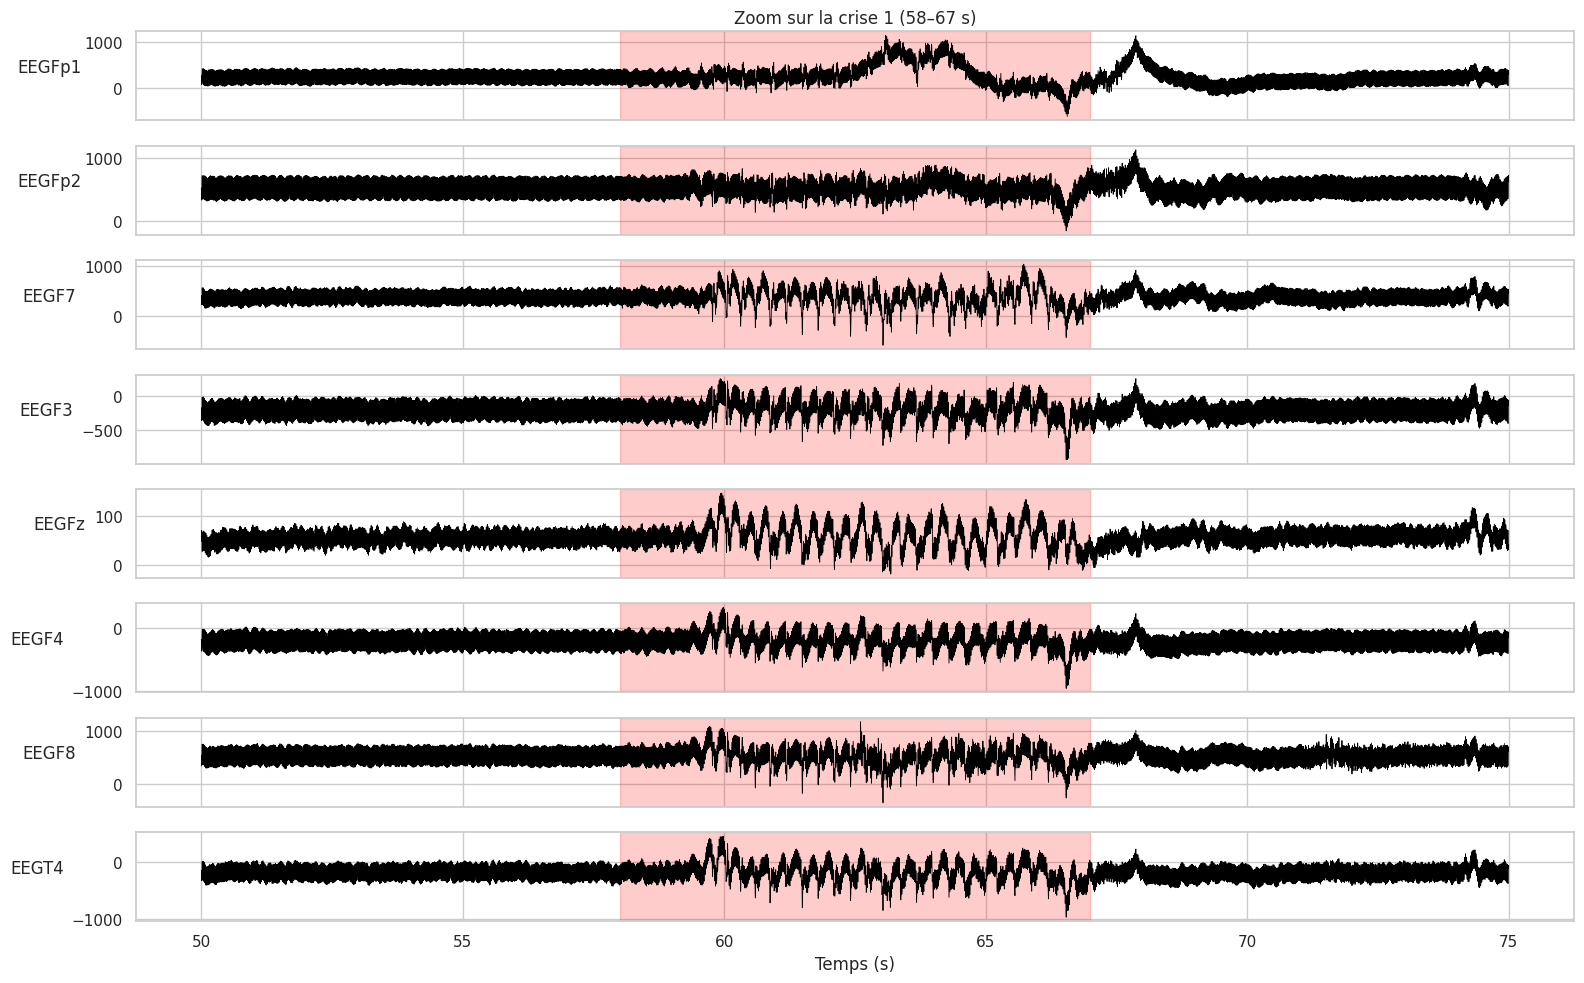

In [14]:
# Question 2 : signal en fonction du temps, crises annotées en rouge
def shade(ax, intervals, color="red", alpha=0.25, label=None):
    for i, (s, e) in enumerate(intervals):
        ax.axvspan(s, e, color=color, alpha=alpha, label=label if i == 0 else None)

CH_PLOT = "EEGF3" if "EEGF3" in EEG_CHANNELS else EEG_CHANNELS[0]
sz_demo = seizure_table(REC_DEMO)
ivals = list(zip(sz_demo["Début (s)"], sz_demo["Fin (s)"]))

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(eeg["Time"], eeg[CH_PLOT], lw=0.3, color="black")
shade(ax, ivals, label="Crise annotée")
ax.set(title=f"Signal EEG — {REC_DEMO} — canal {CH_PLOT}", xlabel="Temps (s)", ylabel="Amplitude (µV)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

# Zoom sur la première crise, plusieurs canaux
s0, e0 = ivals[0]
win = (eeg["Time"] >= s0 - 8) & (eeg["Time"] <= e0 + 8)
chans = EEG_CHANNELS[:8]
fig, axes = plt.subplots(len(chans), 1, figsize=(16, 10), sharex=True)
for ax, ch in zip(axes, chans):
    ax.plot(eeg.loc[win, "Time"], eeg.loc[win, ch], lw=0.6, color="black")
    ax.axvspan(s0, e0, color="red", alpha=0.2)
    ax.set_ylabel(ch, rotation=0, labelpad=25)
axes[0].set_title(f"Zoom sur la crise 1 ({s0:.0f}–{e0:.0f} s)")
axes[-1].set_xlabel("Temps (s)"); plt.tight_layout(); plt.show()

**Observation :** pendant les crises, l'amplitude augmente fortement et le signal devient **rythmique et synchrone sur tous les canaux** : des complexes **pointe-onde** réguliers autour de **3 Hz**, typiques des absences. En dehors des crises, le signal est plus irrégulier et de plus faible amplitude.

## Partie II — Exploitation des annotations

### Question 3 — Début, fin et nombre de crises

In [15]:
sz_demo = seizure_table(REC_DEMO)
print(f"{REC_DEMO} : {len(sz_demo)} crises")
sz_demo

230102B-F : 9 crises


,Crise,Début (s),Fin (s),Durée (s)
0,1,58.0,67.0,9.0
1,2,230.0,246.0,16.0
2,3,277.0,287.0,10.0
3,4,373.0,387.0,14.0
4,5,454.0,462.0,8.0
5,6,641.0,661.0,20.0
6,7,956.0,980.0,24.0
7,8,1058.0,1075.0,17.0
8,9,1203.0,1220.0,17.0


In [16]:
# Même tableau pour tous les enregistrements annotés
print("Nombre total de crises retenues :", len(SEIZURES))
SEIZURES.groupby("ID").agg(Nb_crises=("Crise", "count"),
                           Durée_tot_s=("Durée (s)", "sum")).sort_values("Nb_crises", ascending=False)

Nombre total de crises retenues : 82


,Nb_crises,Durée_tot_s
ID,,
210504B-C,11,127.0
210914B-A,11,176.0
230102B-F,9,135.0
211027B-C,8,123.0
230105B-H,7,38.0
230718A-A,7,67.0
211104B-D,5,40.0
230406B-A,4,44.0
230224B-B,3,46.0


### Question 4 — Statistiques sur les crises

--- 230102B-F ---


,Valeur
Nb crises,9.00
Durée moyenne (s),15.00
Durée min (s),8.00
Durée max (s),24.00
Écart-type durée (s),5.32
Intervalle moyen (s),128.38


--- Tous les enregistrements ---


,Nb crises,Durée moyenne (s),Durée min (s),Durée max (s),Écart-type durée (s),Intervalle moyen (s)
ID,,,,,,
190304A-E,1.0,7.00,7.0,7.0,NaN,NaN
191113A-D,2.0,9.00,5.0,13.0,5.66,161.00
210406A-F,1.0,8.00,8.0,8.0,NaN,NaN
210427B-C,1.0,18.00,18.0,18.0,NaN,NaN
210504B-C,11.0,11.55,2.0,60.0,16.72,160.10
210914B-A,11.0,16.00,4.0,49.0,15.71,84.80
210928B-B,2.0,27.50,25.0,30.0,3.54,108.00
211027B-C,8.0,15.38,8.0,47.0,13.17,130.29
211104B-D,5.0,8.00,6.0,10.0,1.41,152.75


,Global
Nb crises,82.00
Durée moyenne (s),13.32
Durée min (s),2.00
Durée max (s),60.00
Intervalle moyen (s),220.39


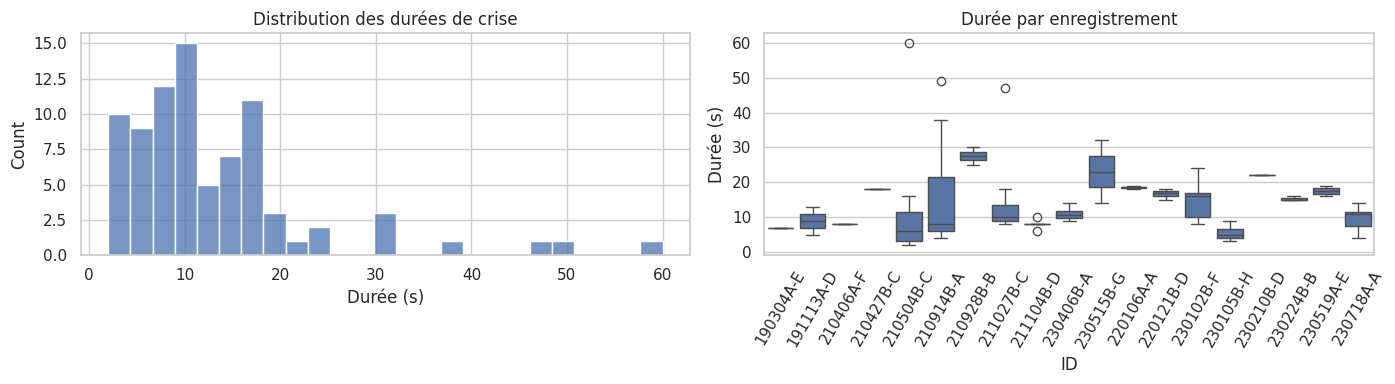

In [17]:
def seizure_stats(t):
    t = t.sort_values("Début (s)")
    gaps = (t["Début (s)"].values[1:] - t["Fin (s)"].values[:-1]) if len(t) > 1 else np.array([])
    return pd.Series({"Nb crises": len(t),
                      "Durée moyenne (s)": t["Durée (s)"].mean(),
                      "Durée min (s)": t["Durée (s)"].min(),
                      "Durée max (s)": t["Durée (s)"].max(),
                      "Écart-type durée (s)": t["Durée (s)"].std(),
                      "Intervalle moyen (s)": gaps.mean() if gaps.size else np.nan})

print(f"--- {REC_DEMO} ---")
display(seizure_stats(sz_demo).round(2).to_frame("Valeur"))

print("--- Tous les enregistrements ---")
per_rec = SEIZURES.groupby("ID").apply(seizure_stats).round(2)
display(per_rec)
glob_stats = pd.Series({"Nb crises": len(SEIZURES), "Durée moyenne (s)": SEIZURES["Durée (s)"].mean(),
                        "Durée min (s)": SEIZURES["Durée (s)"].min(), "Durée max (s)": SEIZURES["Durée (s)"].max(),
                        "Intervalle moyen (s)": per_rec["Intervalle moyen (s)"].mean()})
display(glob_stats.round(2).to_frame("Global"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(SEIZURES["Durée (s)"], bins=25, ax=ax[0]).set(title="Distribution des durées de crise", xlabel="Durée (s)")
sns.boxplot(data=SEIZURES, x="ID", y="Durée (s)", ax=ax[1]).set(title="Durée par enregistrement")
ax[1].tick_params(axis="x", rotation=60); plt.tight_layout(); plt.show()

**Les crises ont-elles toutes une durée similaire ?** Non : les durées varient de quelques secondes à près d'une minute, avec une forte variabilité **entre** patients et aussi **chez un même patient**. La majorité des crises durent entre 5 et 20 s.

## Partie III — Construction de la variable cible

### Question 5 — Colonne `Class`

In [18]:
def add_class(df, rec):
    t = df["Time"].values
    cls = np.zeros(len(df), dtype=np.int8)
    for s, e in SEIZURES.loc[SEIZURES["ID"] == rec, ["Début (s)", "Fin (s)"]].values:
        cls[(t >= s) & (t <= e)] = 1
    df["Class"] = cls
    return df

eeg = add_class(eeg, REC_DEMO)
eeg["Class"].value_counts()

,count
Class,
0,279031
1,34569


### Question 6 — Visualisation des deux classes et déséquilibre

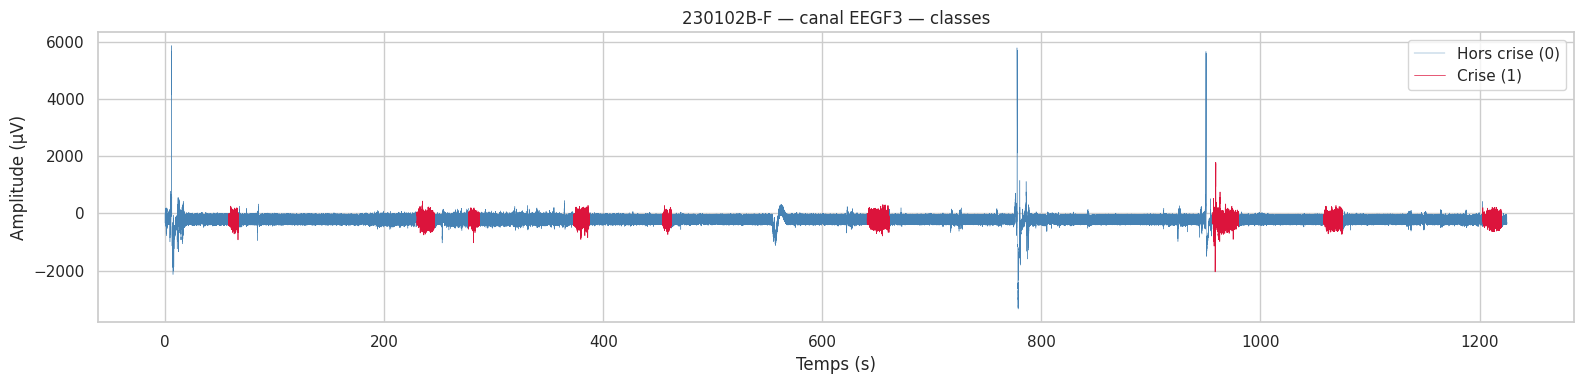

230102B-F : classe 0 = 88.98 %  |  classe 1 = 11.02 %
Global (19 enregistrements annotés) : crises = 3.76 % du temps enregistré


In [19]:
fig, ax = plt.subplots(figsize=(16, 4))
sig = eeg[CH_PLOT].values
ax.plot(eeg["Time"], np.where(eeg["Class"] == 0, sig, np.nan), lw=0.3, color="steelblue", label="Hors crise (0)")
ax.plot(eeg["Time"], np.where(eeg["Class"] == 1, sig, np.nan), lw=0.5, color="crimson", label="Crise (1)")
ax.set(title=f"{REC_DEMO} — canal {CH_PLOT} — classes", xlabel="Temps (s)", ylabel="Amplitude (µV)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

pct = eeg["Class"].value_counts(normalize=True).mul(100).round(2)
print(f"{REC_DEMO} : classe 0 = {pct.get(0, 0)} %  |  classe 1 = {pct.get(1, 0)} %")

# Déséquilibre global sur tous les enregistrements annotés
annotated = summary[summary["Enregistrement"].isin(SEIZURES["ID"])]
sz_time = SEIZURES[SEIZURES["ID"].isin(annotated["Enregistrement"])]["Durée (s)"].sum()
print(f"Global ({len(annotated)} enregistrements annotés) : crises = {100 * sz_time / annotated['Durée (s)'].sum():.2f} % du temps enregistré")

**Le déséquilibre est-il important ?** Oui : les crises ne représentent que quelques pourcents des échantillons. Un modèle naïf qui prédit toujours « pas de crise » aurait une très bonne accuracy sans rien détecter. On en tient compte avec `class_weight="balanced"`, une séparation **stratifiée** et des métriques adaptées (recall, F1).

## Partie IV — Segmentation du signal

### Question 7

- Prétraitement : filtre passe-bande **0,5–40 Hz** (Butterworth ordre 4, sans déphasage) pour retirer la dérive de la ligne de base et le bruit haute fréquence.
- Fenêtres de **2 s** (512 échantillons à 256 Hz) avec **50 % de recouvrement** (pas de 1 s).
- Une fenêtre est de classe 1 si **au moins 50 %** de ses échantillons sont en crise.

In [20]:
WIN_S, OVERLAP = 2.0, 0.5
BANDS = {"Delta": (0.5, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30)}

def bandpass(x, fs, lo=0.5, hi=40, order=4):
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)

def segment(df, fs, win_s=WIN_S, overlap=OVERLAP):
    # Retourne les indices de début de fenêtre, la taille, et la classe de chaque fenêtre
    n_win_samp = int(round(win_s * fs))
    step = int(round(n_win_samp * (1 - overlap)))
    n = len(df)
    starts = np.arange(0, n - n_win_samp + 1, step)
    cum = np.concatenate([[0], np.cumsum(df["Class"].values)])
    frac = (cum[starts + n_win_samp] - cum[starts]) / n_win_samp
    return starts, n_win_samp, (frac >= 0.5).astype(int), frac

starts, n_win_samp, win_class, win_frac = segment(eeg, FS)
print(f"Taille de fenêtre : {n_win_samp} échantillons ({WIN_S} s), pas : {starts[1]-starts[0]} échantillons")
print(f"Nombre de fenêtres : {len(starts)}  |  classe 0 : {(win_class == 0).sum()}  |  classe 1 : {(win_class == 1).sum()}")

Taille de fenêtre : 512 échantillons (2.0 s), pas : 256 échantillons
Nombre de fenêtres : 1224  |  classe 0 : 1080  |  classe 1 : 144


## Partie V et VI — Extraction des caractéristiques (temporelles + fréquentielles)

Pour chaque fenêtre et chaque canal EEG, on calcule les caractéristiques, puis on fait la **moyenne sur les 19 canaux** (une crise d'absence est généralisée, elle touche tous les canaux).

- **Temporelles** : moyenne, écart-type, variance, min, max, amplitude, RMS, énergie.
- **Fréquentielles (FFT)** : puissance Delta, Theta, Alpha, Beta, puissances **relatives**, **fréquence dominante** (≈ 3 Hz pendant une absence).

In [21]:
from numpy.lib.stride_tricks import sliding_window_view

def extract_features(df, fs, channels, rec):
    starts, n_win_samp, win_class, win_frac = segment(df, fs)
    step = starts[1] - starts[0]
    X = df[channels].values.astype(np.float64)
    X = bandpass(X - np.median(X, axis=0), fs)                        # (n_samples, n_ch), offset retiré puis filtré
    hann = np.hanning(n_win_samp)
    freqs = np.fft.rfftfreq(n_win_samp, 1 / fs)
    df_hz = freqs[1] - freqs[0]
    band_idx = {b: (freqs >= lo) & (freqs < hi) for b, (lo, hi) in BANDS.items()}
    total_idx = (freqs >= 0.5) & (freqs < 30)

    acc = {}
    for j in range(X.shape[1]):                                        # canal par canal (mémoire)
        w = sliding_window_view(X[:, j], n_win_samp)[::step][:len(starts)]   # (n_win, n_win_samp)
        feats = {
            "Mean": w.mean(1), "Std": w.std(1), "Variance": w.var(1),
            "Min": w.min(1), "Max": w.max(1),
        }
        feats["Amplitude"] = feats["Max"] - feats["Min"]
        feats["RMS"] = np.sqrt((w ** 2).mean(1))
        feats["Energy"] = (w ** 2).sum(1)
        psd = np.abs(np.fft.rfft((w - w.mean(1, keepdims=True)) * hann, axis=1)) ** 2 / (fs * (hann ** 2).sum())
        total = psd[:, total_idx].sum(1) * df_hz
        for b, idx in band_idx.items():
            feats[f"P_{b}"] = psd[:, idx].sum(1) * df_hz
            feats[f"Rel_{b}"] = feats[f"P_{b}"] / (total + 1e-12)
        feats["Peak_Freq"] = freqs[total_idx][psd[:, total_idx].argmax(1)]
        for k, v in feats.items():
            acc.setdefault(k, []).append(v)

    out = pd.DataFrame({k: np.mean(v, axis=0) for k, v in acc.items()})
    out.insert(0, "t_end", (starts + n_win_samp) / fs)
    out.insert(0, "t_start", starts / fs)
    out.insert(0, "Window", np.arange(1, len(starts) + 1))
    out.insert(0, "Recording", rec)
    out["Seizure_frac"] = win_frac
    out["Class"] = win_class
    return out

feat_demo = extract_features(eeg, FS, EEG_CHANNELS, REC_DEMO)
feat_demo.head()

,Recording,Window,t_start,t_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,P_Delta,Rel_Delta,P_Theta,Rel_Theta,P_Alpha,Rel_Alpha,P_Beta,Rel_Beta,Peak_Freq,Seizure_frac,Class
0,230102B-F,1,0.0,2.0,-19.330766,304.852786,5.099776e+05,-707.341197,612.208078,1319.549275,305.716970,2.614001e+08,290549.502784,0.755626,79396.332528,0.176964,34771.521582,0.048474,14471.666858,0.018935,1.605263,0.0,0
1,230102B-F,2,1.0,3.0,23.555887,181.270176,1.031783e+05,-429.363507,510.120459,939.483966,183.791465,5.609847e+07,19441.431227,0.920660,527.480474,0.065443,158.880030,0.010098,49.811416,0.003799,2.394737,0.0,0
2,230102B-F,3,2.0,4.0,-24.315319,117.328750,7.021868e+04,-375.153043,273.091508,648.244551,120.052000,3.832408e+07,7600.814578,0.735216,1110.854542,0.214794,305.040486,0.034883,264.530644,0.015108,0.526316,0.0,0
3,230102B-F,4,3.0,5.0,36.959583,369.839757,3.776084e+05,-888.346527,1047.673755,1936.020281,372.470268,1.940393e+08,151429.381130,0.906604,25590.409745,0.081592,6621.171318,0.009634,3609.633931,0.002169,1.210526,0.0,0
4,230102B-F,5,4.0,6.0,113.424688,1276.370026,1.703159e+06,-1242.702463,4649.229443,5891.931907,1281.420841,8.787574e+08,221136.721413,0.953381,13805.805377,0.031892,4501.431573,0.010960,1669.828175,0.003766,0.526316,0.0,0


### Question 8 — Construction du dataset complet (tous les enregistrements annotés)

In [22]:
FEATURES_CSV = OUT_DIR / "features_windows.csv"

frames = []
for f in DATA_FILES:
    rec = recording_id(f)
    if rec not in set(SEIZURES["ID"]):
        continue
    d, fs = load_eeg(f)
    chans = [c for c in d.columns if c.startswith("EEG")]
    d = add_class(d, rec)
    frames.append(extract_features(d, fs, chans, rec))
    print(f"{rec}: {len(frames[-1])} fenêtres, {frames[-1]['Class'].sum()} en crise")
    del d

dataset = pd.concat(frames, ignore_index=True)
dataset.to_csv(FEATURES_CSV, index=False)

print("\nNombre total de fenêtres :", len(dataset))
print("Fenêtres classe 0       :", (dataset["Class"] == 0).sum())
print("Fenêtres classe 1       :", (dataset["Class"] == 1).sum(),
      f"({100 * dataset['Class'].mean():.2f} %)")
print("Dataset sauvegardé dans :", FEATURES_CSV)
dataset.head()

190304A-E: 1574 fenêtres, 8 en crise
191113A-D: 1809 fenêtres, 20 en crise
210406A-F: 1453 fenêtres, 9 en crise
210427B-C: 1245 fenêtres, 19 en crise
210504B-C: 3120 fenêtres, 138 en crise
210914B-A: 1204 fenêtres, 187 en crise
210928B-B: 1343 fenêtres, 57 en crise
211027B-C: 1254 fenêtres, 131 en crise
211104B-D: 1209 fenêtres, 45 en crise
220106A-A: 1220 fenêtres, 39 en crise
220121B-D: 1291 fenêtres, 53 en crise
230102B-F: 1224 fenêtres, 144 en crise
230105B-H: 3599 fenêtres, 45 en crise
230210B-D: 1172 fenêtres, 23 en crise
230224B-B: 1427 fenêtres, 49 en crise
230406B-A: 1224 fenêtres, 48 en crise
230515B-G: 1206 fenêtres, 48 en crise
230519A-E: 1215 fenêtres, 37 en crise
230718A-A: 1205 fenêtres, 74 en crise

Nombre total de fenêtres : 28994
Fenêtres classe 0       : 27820
Fenêtres classe 1       : 1174 (4.05 %)
Dataset sauvegardé dans : /content/drive/MyDrive/DataMining_resultats/features_windows.csv


,Recording,Window,t_start,t_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,P_Delta,Rel_Delta,P_Theta,Rel_Theta,P_Alpha,Rel_Alpha,P_Beta,Rel_Beta,Peak_Freq,Seizure_frac,Class
0,190304A-E,1,0.0,2.0,-0.505455,14.947595,280.270954,-71.374776,47.366508,118.741284,14.962571,143964.587507,77.520121,0.503160,16.238060,0.188821,9.412402,0.172234,8.224109,0.135785,1.763158,0.0,0
1,190304A-E,2,1.0,3.0,-0.000431,20.628366,476.422142,-71.759858,57.754914,129.514772,20.639551,244239.875035,54.022989,0.213564,35.746348,0.179087,81.394365,0.412561,38.901728,0.194787,7.263158,0.0,0
2,190304A-E,3,2.0,4.0,0.378373,19.862059,427.881238,-49.581974,53.875593,103.457567,19.881903,219387.473800,38.811663,0.259766,26.816931,0.156268,69.501271,0.403426,26.954335,0.180540,5.921053,0.0,0
3,190304A-E,4,3.0,5.0,-0.138495,24.918787,677.735661,-63.126073,70.943268,134.069340,24.929745,347304.597353,32.235461,0.102494,34.126260,0.133301,270.373892,0.622148,44.284376,0.142058,8.447368,0.0,0
4,190304A-E,5,4.0,6.0,0.795787,27.722296,834.994497,-64.426203,92.004140,156.430343,27.739789,428078.310781,53.966120,0.133810,58.833536,0.147162,192.464422,0.485364,91.716037,0.233663,8.842105,0.0,0


In [23]:
# Format demandé par l'énoncé
cols_enonce = ["Window", "Mean", "Std", "Variance", "Min", "Max", "RMS", "Energy", "Class"]
dataset[dataset["Recording"] == REC_DEMO][cols_enonce].head(10)

,Window,Mean,Std,Variance,Min,Max,RMS,Energy,Class
16722,1,-19.330766,304.852786,5.099776e+05,-707.341197,612.208078,305.716970,2.614001e+08,0
16723,2,23.555887,181.270176,1.031783e+05,-429.363507,510.120459,183.791465,5.609847e+07,0
16724,3,-24.315319,117.328750,7.021868e+04,-375.153043,273.091508,120.052000,3.832408e+07,0
16725,4,36.959583,369.839757,3.776084e+05,-888.346527,1047.673755,372.470268,1.940393e+08,0
16726,5,113.424688,1276.370026,1.703159e+06,-1242.702463,4649.229443,1281.420841,8.787574e+08,0
16727,6,-100.348919,1497.234811,2.293095e+06,-1689.719829,4997.183695,1500.997586,1.179649e+09,0
16728,7,-70.495928,1001.994736,1.412548e+06,-1761.242429,4847.901303,1005.280395,7.261151e+08,0
16729,8,65.377511,476.021205,1.181267e+06,-1294.177079,1154.182644,485.209264,6.071772e+08,0
16730,9,-19.813518,347.991563,9.868423e+05,-1296.839422,553.467619,349.876749,5.055377e+08,0
16731,10,2.217163,271.181528,5.185242e+05,-1066.392779,390.706007,272.291476,2.666605e+08,0


### Question 9 — Domaine temporel vs domaine fréquentiel

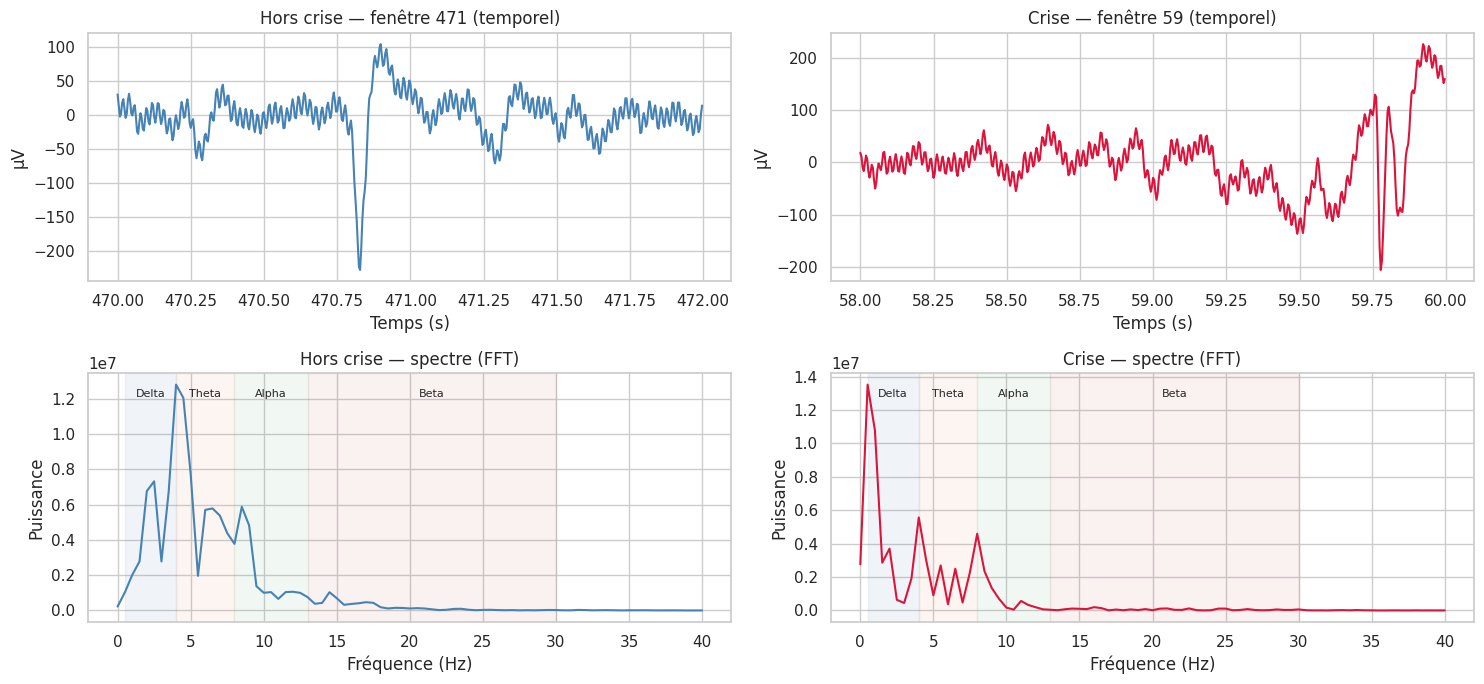

In [24]:
d_demo = feat_demo
i_sz = int(d_demo.loc[d_demo["Seizure_frac"] == 1, "Window"].iloc[0]) - 1 if (d_demo["Seizure_frac"] == 1).any() else int(d_demo["Class"].idxmax())
i_ok = int(d_demo.loc[d_demo["Class"] == 0, "Window"].iloc[len(d_demo) // 3]) - 1

x_raw = eeg[[CH_PLOT]].values.astype(float)
x_f = bandpass(x_raw - np.median(x_raw), FS)[:, 0]
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for col, (i, name, color) in enumerate([(i_ok, "Hors crise", "steelblue"), (i_sz, "Crise", "crimson")]):
    s = starts[i]
    seg = x_f[s:s + n_win_samp]
    t = np.arange(n_win_samp) / FS + s / FS
    axes[0, col].plot(t, seg, color=color)
    axes[0, col].set(title=f"{name} — fenêtre {i+1} (temporel)", xlabel="Temps (s)", ylabel="µV")
    spec = np.abs(np.fft.rfft(seg * np.hanning(n_win_samp))) ** 2
    fr = np.fft.rfftfreq(n_win_samp, 1 / FS)
    m = fr <= 40
    axes[1, col].plot(fr[m], spec[m], color=color)
    for b, (lo, hi) in BANDS.items():
        axes[1, col].axvspan(lo, hi, alpha=0.08, color=f"C{list(BANDS).index(b)}")
        axes[1, col].text((lo + hi) / 2, axes[1, col].get_ylim()[1] * 0.9 if spec[m].max() else 0, b, ha="center", fontsize=8)
    axes[1, col].set(title=f"{name} — spectre (FFT)", xlabel="Fréquence (Hz)", ylabel="Puissance")
plt.tight_layout(); plt.show()

Pendant une crise, le spectre présente un **pic net autour de 3 Hz** (bande Delta/Theta) avec une puissance bien supérieure à celle d'une fenêtre normale.

## Partie VII — Analyse exploratoire des caractéristiques

### Question 10 — Comparaison des deux classes

In [25]:
FEATURES = [c for c in dataset.columns if c not in ("Recording", "Window", "t_start", "t_end", "Seizure_frac", "Class")]

cmp = dataset.groupby("Class")[FEATURES].mean().T
cmp.columns = ["Classe 0 (moyenne)", "Classe 1 (moyenne)"]
cmp["Rapport 1/0"] = cmp.iloc[:, 1] / cmp.iloc[:, 0].replace(0, np.nan)
cmp.round(3)

,Classe 0 (moyenne),Classe 1 (moyenne),Rapport 1/0
Mean,-0.001,-3.200000e-02,60.829
Std,36.991,1.281540e+02,3.464
Variance,10540.015,2.712935e+04,2.574
Min,-91.693,-3.129950e+02,3.414
Max,92.527,2.817480e+02,3.045
Amplitude,184.220,5.947430e+02,3.228
RMS,37.185,1.283900e+02,3.453
Energy,5451727.890,1.393951e+07,2.557
P_Delta,4746.702,1.092732e+04,2.302
Rel_Delta,0.639,6.930000e-01,1.085


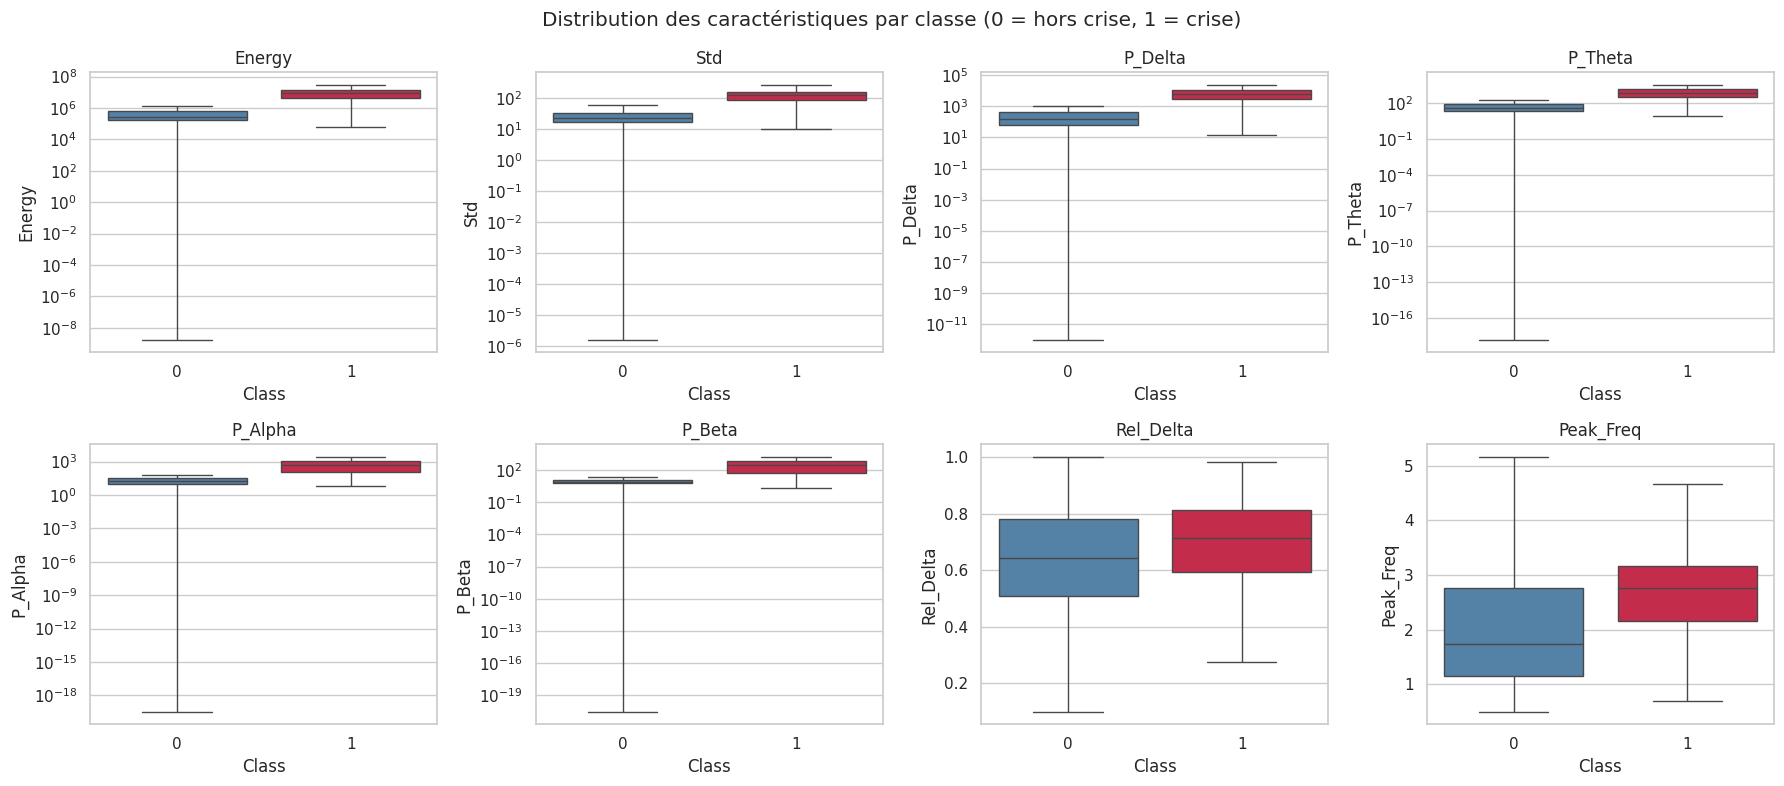

In [26]:
show = ["Energy", "Std", "P_Delta", "P_Theta", "P_Alpha", "P_Beta", "Rel_Delta", "Peak_Freq"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), show):
    sns.boxplot(data=dataset, x="Class", y=f, ax=ax, showfliers=False, palette=["steelblue", "crimson"])
    if dataset[f].min() > 0 and f not in ("Peak_Freq",) and not f.startswith("Rel_"):
        ax.set_yscale("log")
    ax.set_title(f)
plt.suptitle("Distribution des caractéristiques par classe (0 = hors crise, 1 = crise)")
plt.tight_layout(); plt.show()

### Question 11 — Matrice de corrélation

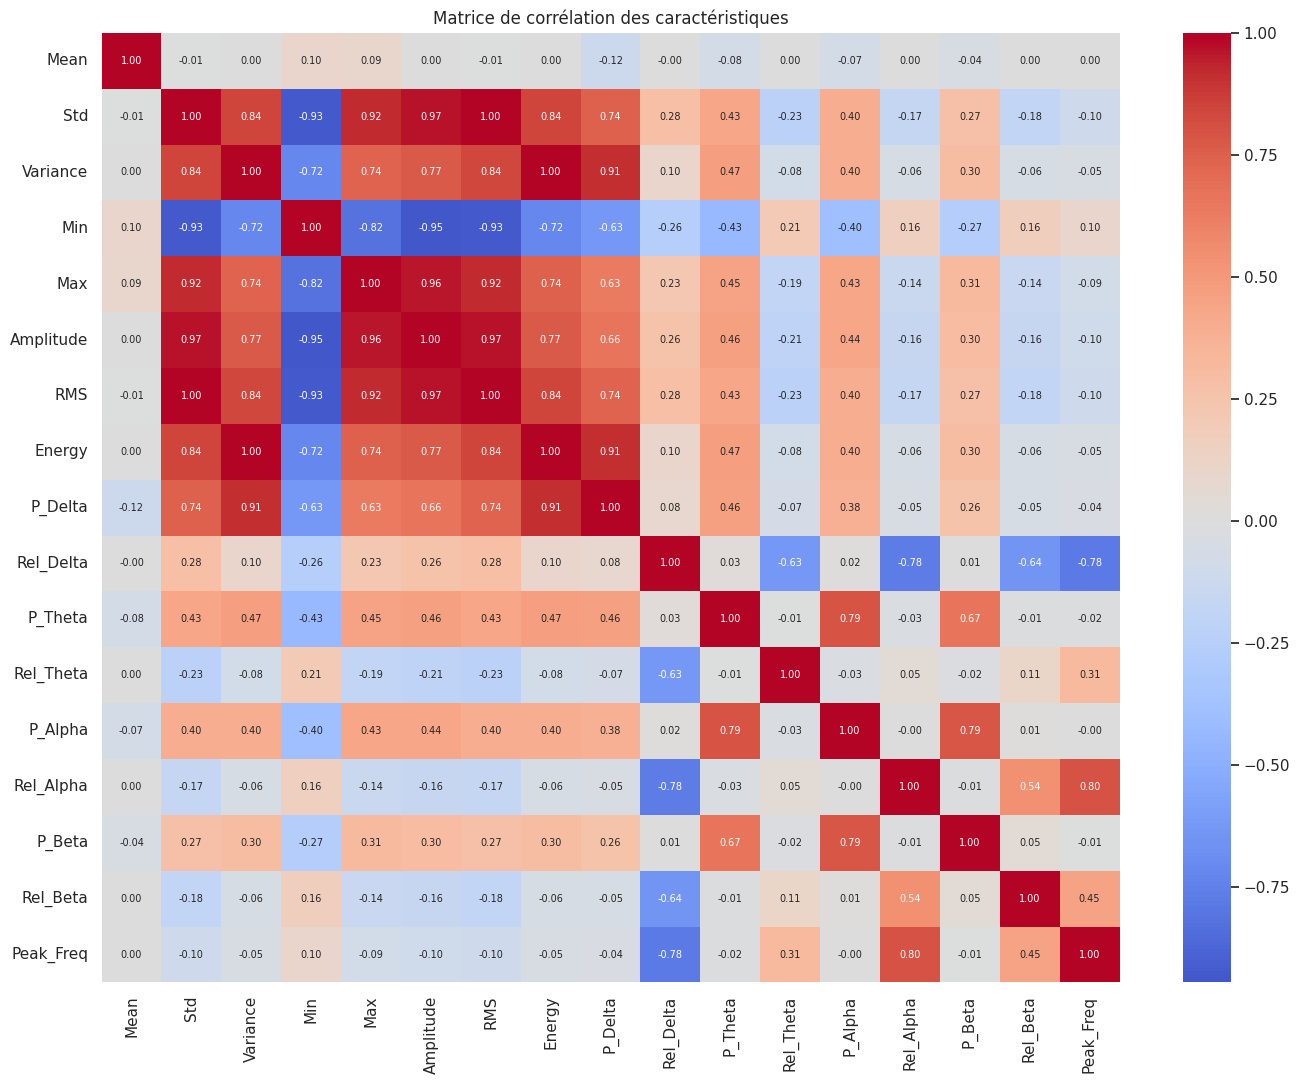

Paires les plus corrélées (|r| > 0.9) :


,Feature 1,Feature 2,corr
35,Variance,Energy,0.999965
20,Std,RMS,0.999965
70,Amplitude,RMS,0.968854
19,Std,Amplitude,0.968827
58,Max,Amplitude,0.960051
46,Min,Amplitude,-0.946424
47,Min,RMS,-0.928636
17,Std,Min,-0.928606
59,Max,RMS,0.920020
18,Std,Max,0.919998


In [27]:
corr = dataset[FEATURES].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matrice de corrélation des caractéristiques"); plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
             .rename("corr").reset_index().rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"}))
print("Paires les plus corrélées (|r| > 0.9) :")
pairs[pairs["corr"].abs() > 0.9].sort_values("corr", key=abs, ascending=False)

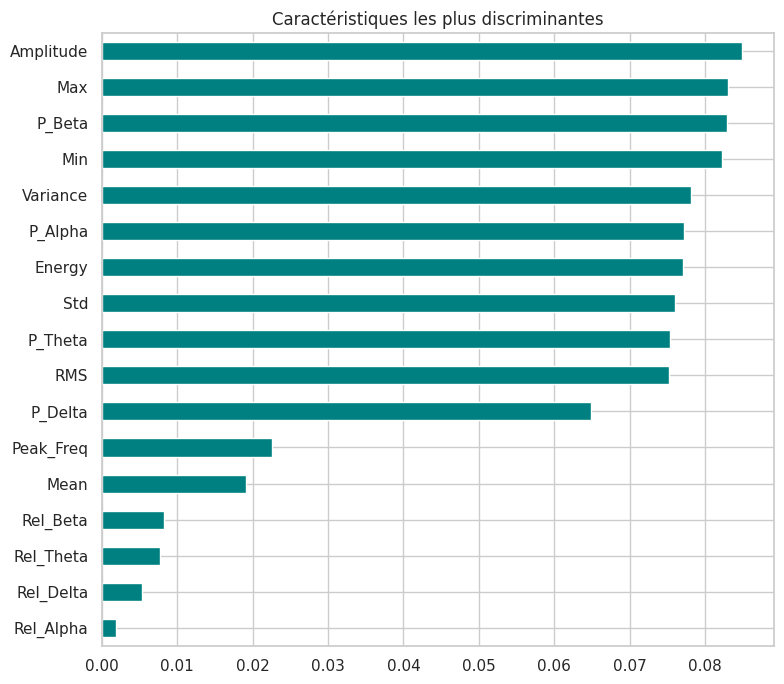

,Info. mutuelle,|d de Cohen|
Amplitude,0.085,1.146
Max,0.083,0.955
P_Beta,0.083,0.309
Min,0.082,1.244
Variance,0.078,0.149
P_Alpha,0.077,0.421
Energy,0.077,0.148
Std,0.076,1.160
P_Theta,0.075,0.169
RMS,0.075,1.157


In [28]:
# Pouvoir discriminant : information mutuelle + taille d'effet (d de Cohen)
from sklearn.feature_selection import mutual_info_classif

y_all = dataset["Class"].values
mi = mutual_info_classif(dataset[FEATURES], y_all, random_state=0)
g0, g1 = dataset[y_all == 0][FEATURES], dataset[y_all == 1][FEATURES]
cohen_d = (g1.mean() - g0.mean()) / np.sqrt((g0.var() + g1.var()) / 2)
disc = pd.DataFrame({"Info. mutuelle": mi, "|d de Cohen|": cohen_d.abs()}, index=FEATURES).sort_values("Info. mutuelle", ascending=False)

disc["Info. mutuelle"].plot.barh(figsize=(8, 7), color="teal").invert_yaxis()
plt.title("Caractéristiques les plus discriminantes"); plt.tight_layout(); plt.show()
disc.round(3)

**Réponses :**
1. **Fortement corrélées** : Std, Variance, RMS, Énergie et Amplitude (elles mesurent toutes la « taille » du signal), ainsi que Min/Max entre elles et les puissances de bandes avec l'énergie.
2. **Redondance** : oui. Variance = Std², Énergie ∝ RMS², Amplitude = Max − Min. Garder une seule de ces variables apporterait presque la même information.
3. **Les plus discriminantes** : voir le classement ci-dessus (typiquement l'énergie/la puissance Delta-Theta et la fréquence dominante). La moyenne de la fenêtre est peu discriminante (le signal filtré est centré).

## Partie VIII — Construction des modèles

Séparation **80 % / 20 % stratifiée**. Chaque modèle est un `Pipeline` (standardisation + classifieur) pour éviter toute fuite d'information du jeu de test. Les classes déséquilibrées sont compensées par `class_weight`.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

X = dataset[FEATURES].values
y = dataset["Class"].values
idx = np.arange(len(dataset))
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, idx, test_size=0.2, stratify=y, random_state=42)
print(f"Train : {len(y_train)} fenêtres ({100*y_train.mean():.2f} % crise)")
print(f"Test  : {len(y_test)} fenêtres ({100*y_test.mean():.2f} % crise)")

Train : 23195 fenêtres (4.05 % crise)
Test  : 5799 fenêtres (4.05 % crise)


### Question 12 — Entraînement des modèles

In [30]:
MODELS = {
    "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=10, min_samples_leaf=5,
                                                                            class_weight="balanced", random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                            class_weight="balanced_subsample",
                                                                            n_jobs=-1, random_state=42)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance")),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")),
}

fitted, preds = {}, {}
for name, model in MODELS.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    preds[name] = model.predict(X_test)
    print(f"{name} entraîné")

Decision Tree entraîné
Random Forest entraîné
KNN entraîné
SVM entraîné


## Partie IX — Évaluation des modèles

In [31]:
def scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-score": f1_score(y_true, y_pred, zero_division=0)}

results = pd.DataFrame({name: scores(y_test, p) for name, p in preds.items()}).T
results.index.name = "Modèle"
results.round(4)

,Accuracy,Precision,Recall,F1-score
Modèle,,,,
Decision Tree,0.9460,0.4156,0.8170,0.5509
Random Forest,0.9831,0.8341,0.7277,0.7773
KNN,0.9788,0.7917,0.6468,0.7119
SVM,0.9507,0.4449,0.8766,0.5903


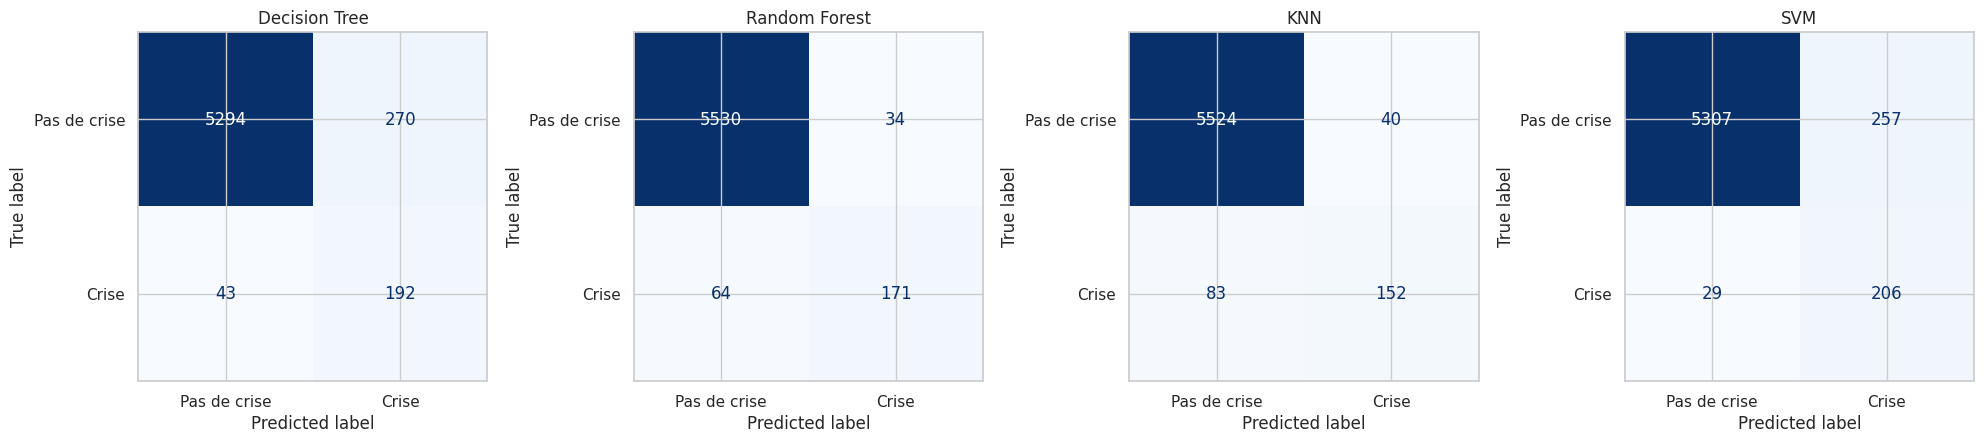

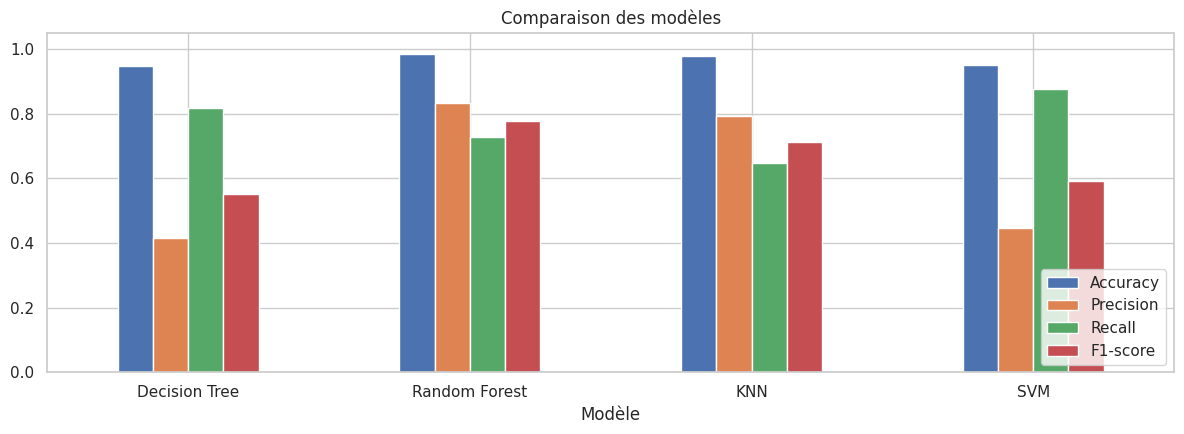

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Pas de crise", "Crise"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

results.plot.bar(figsize=(12, 4.5), rot=0, ylim=(0, 1.05))
plt.title("Comparaison des modèles"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## Question 13 — Quelle métrique privilégier ?

Démonstration avec un modèle « naïf » qui prédit **toujours** « pas de crise » :

In [33]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pd.DataFrame({"Toujours 'pas de crise'": scores(y_test, dummy.predict(X_test))}).T.round(4)

,Accuracy,Precision,Recall,F1-score
Toujours 'pas de crise',0.9595,0.0,0.0,0.0


Ce modèle obtient une **accuracy très élevée** alors qu'il ne détecte **aucune crise** (recall = 0). L'accuracy est dominée par la classe majoritaire et ne reflète pas la capacité à détecter les crises.

- **Recall (sensibilité)** : proportion des crises réellement détectées. En médical, **rater une crise (faux négatif) est l'erreur la plus grave** → c'est la métrique prioritaire.
- **Precision** : proportion des alarmes qui sont de vraies crises. Importante pour éviter trop de fausses alarmes.
- **F1-score** : compromis entre les deux, adapté aux classes déséquilibrées → c'est le critère retenu pour choisir le meilleur modèle, en vérifiant que le recall reste élevé.

In [34]:
BEST = results["F1-score"].idxmax()
print("Meilleur modèle (F1) :", BEST)
print(classification_report(y_test, preds[BEST], target_names=["Pas de crise", "Crise"], digits=3))

Meilleur modèle (F1) : Random Forest
              precision    recall  f1-score   support

Pas de crise      0.989     0.994     0.991      5564
       Crise      0.834     0.728     0.777       235

    accuracy                          0.983      5799
   macro avg      0.911     0.861     0.884      5799
weighted avg      0.982     0.983     0.983      5799



### Évaluation complémentaire : validation par enregistrement

Avec un découpage aléatoire, deux fenêtres voisines (qui se chevauchent à 50 %) peuvent se retrouver l'une en train, l'autre en test, ce qui rend les scores **optimistes**. Une évaluation plus réaliste consiste à tester sur des **enregistrements jamais vus** (`GroupKFold`).

In [35]:
from sklearn.model_selection import GroupKFold

groups = dataset["Recording"].values
n_splits = min(5, len(np.unique(groups)))
if n_splits >= 2:
    rows = []
    for name in [BEST]:
        y_pred_cv = np.zeros_like(y)
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            m = clone(MODELS[name]).fit(X[tr], y[tr])
            y_pred_cv[te] = m.predict(X[te])
        rows.append(pd.Series(scores(y, y_pred_cv), name=f"{name} (par enregistrement)"))
    display(pd.concat([results.loc[[BEST]], pd.DataFrame(rows)]).round(4))
else:
    print("Un seul enregistrement : validation par enregistrement impossible.")

,Accuracy,Precision,Recall,F1-score
Random Forest,0.9831,0.8341,0.7277,0.7773
Random Forest (par enregistrement),0.9772,0.7433,0.6661,0.7026


## Partie X — Détection temporelle des crises

### Question 14

On prend un enregistrement de démonstration. Pour éviter toute fuite, le meilleur modèle est **ré-entraîné sur tous les autres enregistrements**, puis appliqué à toutes les fenêtres de celui-ci.

Post-traitement : lissage des prédictions (filtre médian sur 3 fenêtres), puis fusion des fenêtres consécutives positives en intervalles.

In [36]:
MIN_EVENT_S = 2.0   # on ignore les détections plus courtes
MERGE_GAP_S = 1.0   # on fusionne deux détections séparées de moins de 1 s

def windows_to_intervals(t_start, t_end, pred, min_len=MIN_EVENT_S, gap=MERGE_GAP_S):
    events, cur = [], None
    for s, e, p in zip(t_start, t_end, pred):
        if p:
            cur = [s, e] if cur is None else [cur[0], e]
        elif cur is not None:
            events.append(cur); cur = None
    if cur is not None:
        events.append(cur)
    merged = []
    for ev in events:
        if merged and ev[0] - merged[-1][1] <= gap:
            merged[-1][1] = max(merged[-1][1], ev[1])
        else:
            merged.append(ev)
    return [(s, e) for s, e in merged if e - s >= min_len]


def detect(rec, model_name=BEST, smooth=3):
    d_rec = dataset[dataset["Recording"] == rec].sort_values("t_start")
    others = dataset[dataset["Recording"] != rec]
    if others["Class"].nunique() == 2:
        model = clone(MODELS[model_name]).fit(others[FEATURES].values, others["Class"].values)
    else:  # un seul enregistrement disponible : on réutilise le modèle de la partie IX
        model = fitted[model_name]
    raw = model.predict(d_rec[FEATURES].values)
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    ev = windows_to_intervals(d_rec["t_start"].values, d_rec["t_end"].values, sm)
    return d_rec, raw, sm, ev


def match_events(true_iv, pred_iv):
    rows, used = [], set()
    for k, (ts, te) in enumerate(true_iv, 1):
        hit = [j for j, (ps, pe) in enumerate(pred_iv) if ps < te and pe > ts]
        if hit:
            used.update(hit)
            ps, pe = pred_iv[hit[0]][0], pred_iv[hit[-1]][1]
            rows.append({"Crise réelle": k, "Début réel": ts, "Fin réelle": te, "Début détecté": ps,
                         "Fin détectée": pe, "Retard début (s)": round(ps - ts, 1), "Écart fin (s)": round(pe - te, 1),
                         "Résultat": "Détectée"})
        else:
            rows.append({"Crise réelle": k, "Début réel": ts, "Fin réelle": te, "Résultat": "Manquée"})
    for j, (ps, pe) in enumerate(pred_iv):
        if j not in used:
            rows.append({"Début détecté": ps, "Fin détectée": pe, "Résultat": "Fausse alarme"})
    return pd.DataFrame(rows)


d_rec, raw_pred, sm_pred, events = detect(REC_DEMO)
true_iv = list(zip(sz_demo["Début (s)"], sz_demo["Fin (s)"]))
for k, (s, e) in enumerate(events, 1):
    print(f"Crise détectée {k} : {s:.1f} s → {e:.1f} s")
match = match_events(true_iv, events)
match

Crise détectée 1 : 15.0 s → 18.0 s
Crise détectée 2 : 58.0 s → 68.0 s
Crise détectée 3 : 230.0 s → 247.0 s
Crise détectée 4 : 275.0 s → 284.0 s
Crise détectée 5 : 338.0 s → 342.0 s
Crise détectée 6 : 373.0 s → 387.0 s
Crise détectée 7 : 454.0 s → 463.0 s
Crise détectée 8 : 642.0 s → 661.0 s
Crise détectée 9 : 964.0 s → 975.0 s
Crise détectée 10 : 1058.0 s → 1077.0 s
Crise détectée 11 : 1206.0 s → 1220.0 s


,Crise réelle,Début réel,Fin réelle,Début détecté,Fin détectée,Retard début (s),Écart fin (s),Résultat
0,1.0,58.0,67.0,58.0,68.0,0.0,1.0,Détectée
1,2.0,230.0,246.0,230.0,247.0,0.0,1.0,Détectée
2,3.0,277.0,287.0,275.0,284.0,-2.0,-3.0,Détectée
3,4.0,373.0,387.0,373.0,387.0,0.0,0.0,Détectée
4,5.0,454.0,462.0,454.0,463.0,0.0,1.0,Détectée
5,6.0,641.0,661.0,642.0,661.0,1.0,0.0,Détectée
6,7.0,956.0,980.0,964.0,975.0,8.0,-5.0,Détectée
7,8.0,1058.0,1075.0,1058.0,1077.0,0.0,2.0,Détectée
8,9.0,1203.0,1220.0,1206.0,1220.0,3.0,0.0,Détectée
9,NaN,NaN,NaN,15.0,18.0,NaN,NaN,Fausse alarme


Crises détectées : 9/9 (sensibilité événementielle = 100%)
Fausses alarmes  : 2 (5.9 par heure)


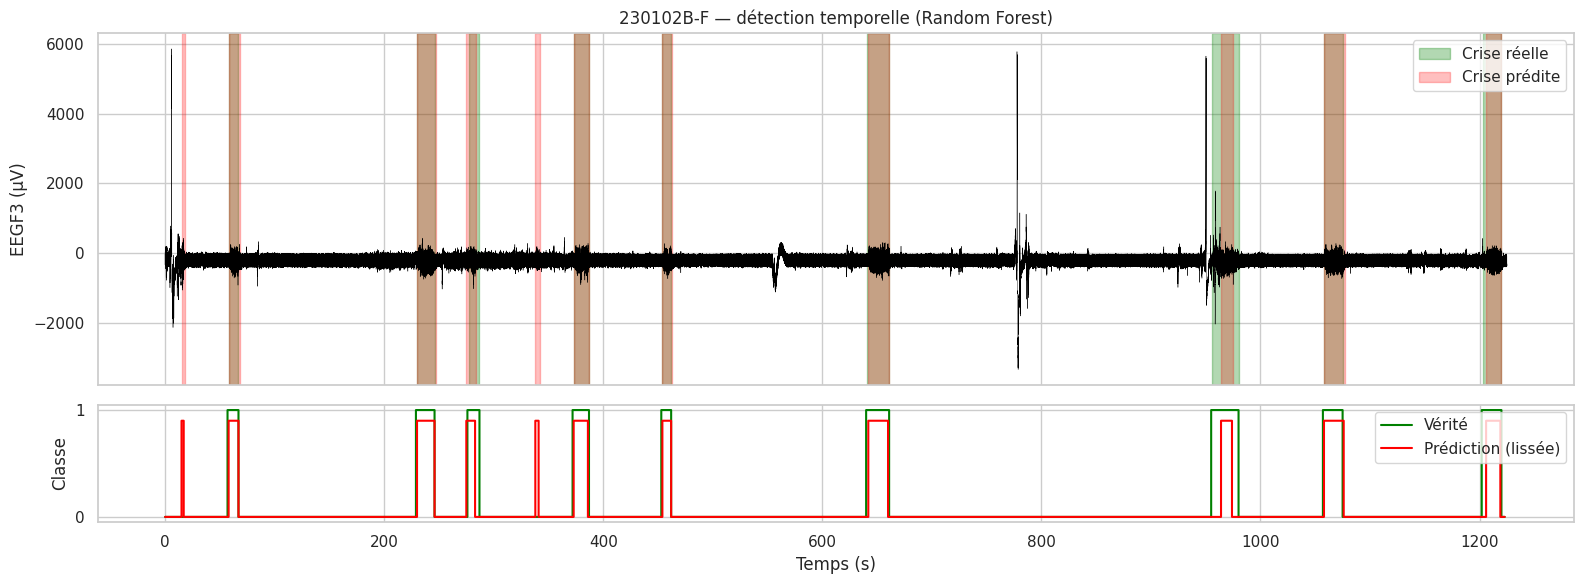

In [37]:
n_true, n_det = len(true_iv), (match["Résultat"] == "Détectée").sum()
n_fa = (match["Résultat"] == "Fausse alarme").sum()
dur_h = eeg["Time"].iloc[-1] / 3600
print(f"Crises détectées : {n_det}/{n_true} (sensibilité événementielle = {n_det / max(n_true, 1):.0%})")
print(f"Fausses alarmes  : {n_fa} ({n_fa / dur_h:.1f} par heure)")

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(eeg["Time"], eeg[CH_PLOT], lw=0.3, color="black")
shade(axes[0], true_iv, color="green", alpha=0.3, label="Crise réelle")
shade(axes[0], events, color="red", alpha=0.25, label="Crise prédite")
axes[0].set(title=f"{REC_DEMO} — détection temporelle ({BEST})", ylabel=f"{CH_PLOT} (µV)")
axes[0].legend(loc="upper right")
axes[1].step(d_rec["t_start"], d_rec["Class"], where="post", color="green", label="Vérité")
axes[1].step(d_rec["t_start"], sm_pred * 0.9, where="post", color="red", label="Prédiction (lissée)")
axes[1].set(xlabel="Temps (s)", yticks=[0, 1], ylabel="Classe"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In [38]:
# Détection sur tous les enregistrements (chacun prédit par un modèle qui ne l'a jamais vu)
all_rows = []
for rec in dataset["Recording"].unique():
    _, _, _, ev = detect(rec)
    t = seizure_table(rec)
    m = match_events(list(zip(t["Début (s)"], t["Fin (s)"])), ev)
    all_rows.append({"Enregistrement": rec, "Crises réelles": len(t),
                     "Détectées": (m["Résultat"] == "Détectée").sum(),
                     "Manquées": (m["Résultat"] == "Manquée").sum(),
                     "Fausses alarmes": (m["Résultat"] == "Fausse alarme").sum()})
event_summary = pd.DataFrame(all_rows)
tot = event_summary[["Crises réelles", "Détectées", "Manquées", "Fausses alarmes"]].sum()
print(f"Sensibilité globale : {tot['Détectées'] / tot['Crises réelles']:.1%} — fausses alarmes : {tot['Fausses alarmes']}")
event_summary

Sensibilité globale : 97.6% — fausses alarmes : 25


,Enregistrement,Crises réelles,Détectées,Manquées,Fausses alarmes
0,190304A-E,1,1,0,0
1,191113A-D,2,0,2,0
2,210406A-F,1,1,0,0
3,210427B-C,1,1,0,5
4,210504B-C,11,11,0,7
5,210914B-A,11,11,0,2
6,210928B-B,2,2,0,0
7,211027B-C,8,8,0,2
8,211104B-D,5,5,0,2
9,220106A-A,2,2,0,0


## Partie XI — Analyse des erreurs du meilleur modèle

In [39]:
cm = confusion_matrix(y_test, preds[BEST])
tn, fp, fn, tp = cm.ravel()
print(f"Vrais positifs  (crise détectée)          : {tp}")
print(f"Vrais négatifs  (normal reconnu)          : {tn}")
print(f"Faux positifs   (fausse alarme)           : {fp}")
print(f"Faux négatifs   (crise manquée)           : {fn}")

err = dataset.iloc[idx_test].copy()
err["Pred"] = preds[BEST]
err["Type"] = np.select([(err.Class == 1) & (err.Pred == 1), (err.Class == 0) & (err.Pred == 0),
                         (err.Class == 0) & (err.Pred == 1)], ["VP", "VN", "FP"], "FN")

# Les erreurs sont-elles aux frontières des crises ? (fenêtres partiellement en crise)
err["Bordure"] = (err["Seizure_frac"] > 0) & (err["Seizure_frac"] < 1)
display(err.groupby("Type")["Bordure"].mean().mul(100).round(1).to_frame("% fenêtres en bordure de crise"))
display(err.groupby("Recording")["Type"].value_counts().unstack(fill_value=0))

Vrais positifs  (crise détectée)          : 171
Vrais négatifs  (normal reconnu)          : 5530
Faux positifs   (fausse alarme)           : 34
Faux négatifs   (crise manquée)           : 64


,% fenêtres en bordure de crise
Type,
FN,42.2
FP,2.9
VN,0.2
VP,5.8


Type,FN,FP,VN,VP
Recording,,,,
190304A-E,0,0,306,0
191113A-D,2,0,353,2
210406A-F,1,0,283,1
210427B-C,1,9,249,3
210504B-C,13,5,551,14
210914B-A,15,2,181,18
210928B-B,4,0,270,12
211027B-C,4,7,238,28
211104B-D,3,1,224,5


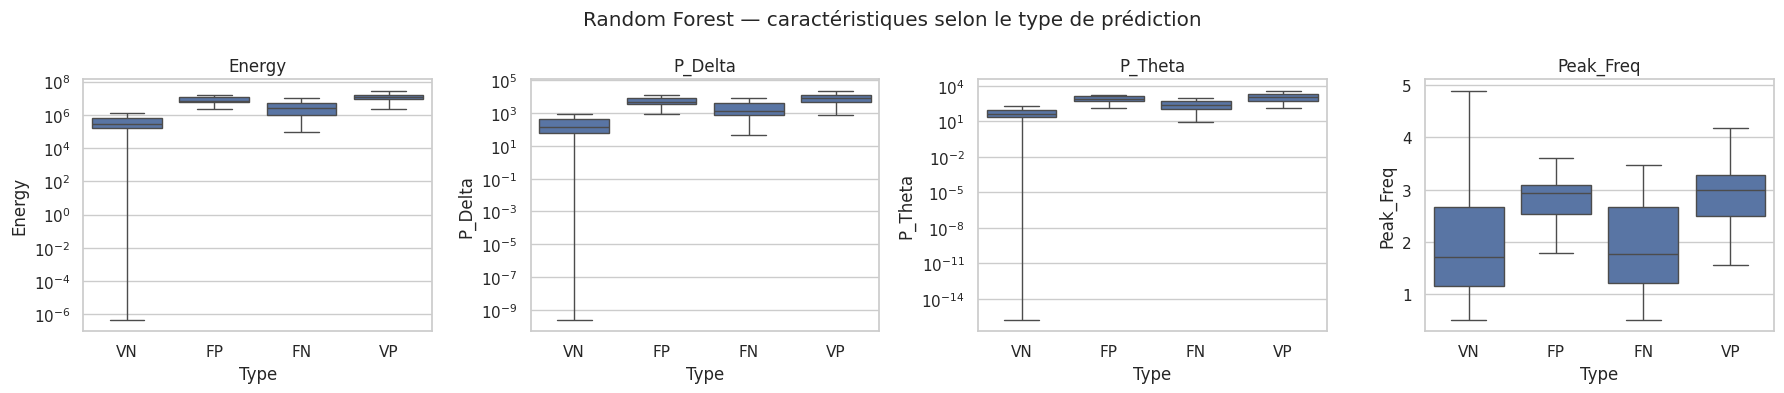

In [40]:
# Comparaison des caractéristiques par type de prédiction
key = ["Energy", "P_Delta", "P_Theta", "Peak_Freq"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
order = ["VN", "FP", "FN", "VP"]
for ax, f in zip(axes, key):
    sns.boxplot(data=err, x="Type", y=f, order=[o for o in order if o in err.Type.unique()], ax=ax, showfliers=False)
    if f != "Peak_Freq":
        ax.set_yscale("log")
    ax.set_title(f)
plt.suptitle(f"{BEST} — caractéristiques selon le type de prédiction"); plt.tight_layout(); plt.show()

**Interprétation :**
- Les **faux négatifs** sont surtout des fenêtres **en bordure** de crise (début/fin) ou des crises de faible amplitude, que le modèle confond avec l'activité normale.
- Les **faux positifs** correspondent souvent à des artefacts (mouvements, clignements des yeux → forte énergie basse fréquence) qui ressemblent à une crise en énergie et en puissance Delta.
- Les **vrais positifs** ont une énergie et une puissance Delta/Theta très élevées et une fréquence dominante proche de 3 Hz.

## Partie XII — Amélioration du système

Deux améliorations testées :
1. **Ajustement du seuil de décision** (Random Forest donne une probabilité) : choisir le seuil qui maximise le F1 sur une partie validation du train, au lieu de 0,5.
2. **Lissage temporel** des prédictions (une crise dure plusieurs secondes : une fenêtre isolée positive est souvent une erreur).

In [41]:
from sklearn.metrics import precision_recall_curve

# 1) Seuil optimal, choisi sur une validation interne (jamais sur le test)
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=1)
rf = clone(MODELS["Random Forest"]).fit(X_tr2, y_tr2)
p_val = rf.predict_proba(X_val)[:, 1]
prec, rec_, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec_[:-1] / (prec[:-1] + rec_[:-1] + 1e-12)
best_thr = thr[f1s.argmax()]
rf_full = clone(MODELS["Random Forest"]).fit(X_train, y_train)
p_test = rf_full.predict_proba(X_test)[:, 1]

# 2) Lissage temporel : appliqué par enregistrement dans l'ordre chronologique
def smooth_by_recording(pred_series):
    out = pred_series.copy()
    for rec, g in dataset.loc[pred_series.index].groupby("Recording"):
        order = g.sort_values("t_start").index
        out.loc[order] = medfilt(pred_series.loc[order].values.astype(float), 3).astype(int)
    return out

full_pred = pd.Series(rf_full.predict(X), index=dataset.index)       # prédiction de toutes les fenêtres
smoothed = smooth_by_recording(full_pred).loc[idx_test].values

improv = pd.DataFrame({
    "RF (seuil 0.5)": scores(y_test, (p_test >= 0.5).astype(int)),
    f"RF (seuil optimisé = {best_thr:.2f})": scores(y_test, (p_test >= best_thr).astype(int)),
    "RF + lissage temporel": scores(y_test, smoothed),
}).T
improv.round(4)

,Accuracy,Precision,Recall,F1-score
RF (seuil 0.5),0.9831,0.8341,0.7277,0.7773
RF (seuil optimisé = 0.45),0.9824,0.8065,0.7447,0.7743
RF + lissage temporel,0.9902,0.9045,0.8468,0.8747


**Autres pistes d'amélioration :**
- Adapter la **taille des fenêtres** (1 s pour mieux localiser les débuts, 4 s pour plus de stabilité) et le recouvrement (75 %).
- **Garder les caractéristiques par canal** au lieu de la moyenne (19 × 17 variables) puis faire une **sélection de variables** (on supprime les redondantes repérées en Q11).
- Ajouter des caractéristiques : entropie spectrale, paramètres de Hjorth, line-length, rapports de bandes (Delta/Alpha), cohérence entre canaux.
- **Optimiser les hyperparamètres** (`GridSearchCV` avec `GroupKFold`).
- Traiter le déséquilibre par **sur-échantillonnage** (SMOTE) ou sous-échantillonnage.
- **Deep learning** (CNN 1D / LSTM) directement sur le signal brut multicanal.

In [42]:
# Sauvegarde des résultats et du meilleur modèle (réutilisable dans une interface)
import joblib
results.to_csv(OUT_DIR / "resultats_modeles.csv")
event_summary.to_csv(OUT_DIR / "detection_par_enregistrement.csv", index=False)
final_model = clone(MODELS[BEST]).fit(X, y)
joblib.dump({"model": final_model, "features": FEATURES, "fs_window_s": WIN_S, "overlap": OVERLAP},
            OUT_DIR / "best_model.joblib")
print("Résultats sauvegardés dans", OUT_DIR)

Résultats sauvegardés dans /content/drive/MyDrive/DataMining_resultats


## Conclusion

La chaîne complète transforme un signal EEG brut en une liste de crises (début / fin). Les caractéristiques énergétiques et spectrales (bande Delta/Theta, fréquence dominante ≈ 3 Hz) séparent bien les crises de l'activité normale. Les modèles d'ensemble (Random Forest) donnent généralement le meilleur compromis précision / rappel. Les principales limites sont la faible taille du jeu de données (une vingtaine de patients), les erreurs en bordure de crise et les artefacts, ainsi que l'optimisme de l'évaluation aléatoire par rapport à une évaluation par patient.

## Influence de la taille des fenêtres (2 s, 5 s, 10 s)

Tout le notebook utilise des fenêtres de **2 s**. On refait ici la même chaîne avec des fenêtres de **5 s** et de **10 s** pour voir ce que ce choix change. Rien n'est modifié dans les sections précédentes : seule la longueur de la fenêtre varie.

Ce qui reste identique pour les trois tailles :
- prétraitement, **50 % de recouvrement**, règle d'étiquetage (fenêtre = crise si **≥ 50 %** de ses échantillons sont en crise) ;
- les 17 caractéristiques, moyennées sur les 19 canaux ;
- le **Random Forest** de `MODELS["Random Forest"]` (mêmes hyperparamètres) ;
- le post-traitement de `detect()` : lissage médian sur 3 fenêtres, fusion des détections séparées de moins de 1 s, durée minimale de 2 s.

Deux évaluations par taille : au niveau **fenêtre** (GroupKFold par enregistrement, 5 plis) et au niveau **crise** (chaque enregistrement est prédit par un modèle entraîné sur les 18 autres).

In [43]:
import time
T0_FENETRES = time.perf_counter()        # pour mesurer la durée de toute la section

WINDOW_SIZES = [2, 5, 10]                # tailles de fenêtre comparées (en secondes)


def extract_features_win(df, fs, channels, rec, win_s):
    # Même calcul que extract_features(), mais avec une taille de fenêtre choisie.
    # extract_features() appelle segment(df, fs) : on remplace segment, le temps de l'appel,
    # par une version qui reçoit win_s. Le code d'origine n'est donc ni copié ni modifié.
    global segment
    segment_origine = segment
    segment = lambda d, f: segment_origine(d, f, win_s=win_s, overlap=OVERLAP)
    try:
        return extract_features(df, fs, channels, rec)
    finally:
        segment = segment_origine        # on remet toujours la fonction d'origine (2 s)


def features_csv(win_s):
    # Le CSV des fenêtres de 2 s existe déjà (Question 8) : on le réutilise tel quel
    return FEATURES_CSV if win_s == WIN_S else OUT_DIR / f"features_windows_{win_s}s.csv"


# On ne lit chaque fichier .mat qu'une seule fois, pour toutes les tailles manquantes
a_calculer = [w for w in WINDOW_SIZES if not features_csv(w).exists()]
if a_calculer:
    frames_win = {w: [] for w in a_calculer}
    for f in DATA_FILES:
        rec = recording_id(f)
        if rec not in set(SEIZURES["ID"]):
            continue                     # enregistrement sans annotation
        d, fs = load_eeg(f)
        chans = [c for c in d.columns if c.startswith("EEG")]
        d = add_class(d, rec)
        for w in a_calculer:
            frames_win[w].append(extract_features_win(d, fs, chans, rec, w))
        del d
    for w in a_calculer:
        pd.concat(frames_win[w], ignore_index=True).to_csv(features_csv(w), index=False)
    del frames_win

DATASETS = {w: pd.read_csv(features_csv(w)) for w in WINDOW_SIZES}
for w, data in DATASETS.items():
    etat = "calculé" if w in a_calculer else "relu depuis le cache"
    print(f"Fenêtres de {w:>2} s : {len(data):>6} fenêtres, {data['Recording'].nunique()} enregistrements "
          f"({etat} : {features_csv(w).name})")

Fenêtres de  2 s :  28994 fenêtres, 19 enregistrements (relu depuis le cache : features_windows.csv)
Fenêtres de  5 s :  11581 fenêtres, 19 enregistrements (calculé : features_windows_5s.csv)
Fenêtres de 10 s :   5779 fenêtres, 19 enregistrements (calculé : features_windows_10s.csv)


### Taille du jeu de données et crises « perdues »

Avec la règle des 50 %, une crise plus courte que la moitié de la fenêtre ne peut étiqueter aucune fenêtre : elle disparaît du jeu d'apprentissage. On compte donc, pour chaque taille, combien de crises annotées gardent **au moins une fenêtre de classe 1**.

In [44]:
def crises_avec_fenetre(data):
    # Nombre de crises annotées recouvertes par au moins une fenêtre étiquetée 1
    n = 0
    for rec, g in data[data["Class"] == 1].groupby("Recording"):
        for s, e in SEIZURES.loc[SEIZURES["ID"] == rec, ["Début (s)", "Fin (s)"]].values:
            n += int(((g["t_start"] < e) & (g["t_end"] > s)).any())
    return n


RECS_ANNOTES = list(DATASETS[WINDOW_SIZES[0]]["Recording"].unique())
N_CRISES = int(SEIZURES["ID"].isin(RECS_ANNOTES).sum())      # crises annotées dans ces enregistrements

lignes = []
for w, data in DATASETS.items():
    n_ok = crises_avec_fenetre(data)
    lignes.append({"Fenêtre (s)": w, "Pas (s)": w * (1 - OVERLAP),
                   "Nb fenêtres": len(data),
                   "Fenêtres en crise": int(data["Class"].sum()),
                   "% fenêtres en crise": round(100 * data["Class"].mean(), 2),
                   "Crises avec ≥ 1 fenêtre": n_ok,
                   "Crises perdues": N_CRISES - n_ok})
stats_fenetres = pd.DataFrame(lignes).set_index("Fenêtre (s)")
print(f"Crises annotées : {N_CRISES} dans {len(RECS_ANNOTES)} enregistrements")
stats_fenetres

Crises annotées : 82 dans 19 enregistrements


,Pas (s),Nb fenêtres,Fenêtres en crise,% fenêtres en crise,Crises avec ≥ 1 fenêtre,Crises perdues
Fenêtre (s),,,,,,
2,1.0,28994,1174,4.05,82,0
5,2.5,11581,448,3.87,81,1
10,5.0,5779,227,3.93,72,10


In [45]:
# Durée des crises annotées : lesquelles sont trop courtes pour chaque taille de fenêtre ?
durees = SEIZURES.loc[SEIZURES["ID"].isin(RECS_ANNOTES), "Durée (s)"]
print(f"Durée des crises : min {durees.min():.1f} s, médiane {durees.median():.1f} s, max {durees.max():.1f} s")
for w in WINDOW_SIZES:
    print(f"  crises de moins de {w / 2:>3.1f} s (moitié d'une fenêtre de {w:>2} s) : {(durees < w / 2).sum():>2}"
          f"   |   de moins de {w:>2} s : {(durees < w).sum():>2}")

Durée des crises : min 2.0 s, médiane 11.0 s, max 60.0 s
  crises de moins de 1.0 s (moitié d'une fenêtre de  2 s) :  0   |   de moins de  2 s :  0
  crises de moins de 2.5 s (moitié d'une fenêtre de  5 s) :  1   |   de moins de  5 s : 10
  crises de moins de 5.0 s (moitié d'une fenêtre de 10 s) : 10   |   de moins de 10 s : 37


### Évaluation pour chaque taille de fenêtre

- **Niveau fenêtre** : GroupKFold par enregistrement (5 plis), comme dans l'évaluation complémentaire de la partie IX.
- **Niveau crise** : même procédure que `detect()` (modèle ré-entraîné sans l'enregistrement testé, lissage médian sur 3 fenêtres, fusion à 1 s, durée minimale 2 s), puis `match_events()`.

In [46]:
RF = MODELS["Random Forest"]             # même modèle et mêmes hyperparamètres que dans la partie VIII
SMOOTH_WIN = 3                           # lissage médian sur 3 fenêtres, comme dans detect()
DUREE_TOTALE_H = sum(dur[r] for r in RECS_ANNOTES) / 3600    # durée cumulée des enregistrements (h)


def eval_fenetres(data):
    # Scores au niveau fenêtre, validation par enregistrement (GroupKFold, 5 plis)
    Xw, yw, gw = data[FEATURES].values, data["Class"].values, data["Recording"].values
    y_cv = np.zeros_like(yw)
    for tr, te in GroupKFold(n_splits=min(5, len(np.unique(gw)))).split(Xw, yw, gw):
        y_cv[te] = clone(RF).fit(Xw[tr], yw[tr]).predict(Xw[te])
    return scores(yw, y_cv)


def detect_win(data, rec, smooth=SMOOTH_WIN):
    # Même logique que detect(), mais sur le jeu de données d'une taille de fenêtre donnée
    d_rec = data[data["Recording"] == rec].sort_values("t_start")
    others = data[data["Recording"] != rec]
    model = clone(RF).fit(others[FEATURES].values, others["Class"].values)
    raw = model.predict(d_rec[FEATURES].values)
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    return windows_to_intervals(d_rec["t_start"].values, d_rec["t_end"].values, sm)


def eval_crises(data):
    # Scores au niveau crise : chaque enregistrement est prédit par un modèle qui ne l'a jamais vu
    n_det = n_miss = n_fa = 0
    retards = []
    for rec in RECS_ANNOTES:
        t = seizure_table(rec)
        m = match_events(list(zip(t["Début (s)"], t["Fin (s)"])), detect_win(data, rec))
        ok = m[m["Résultat"] == "Détectée"]
        n_det += len(ok)
        n_miss += int((m["Résultat"] == "Manquée").sum())
        n_fa += int((m["Résultat"] == "Fausse alarme").sum())
        if len(ok):                      # aucune colonne « Début détecté » si rien n'est détecté
            retards += list((ok["Début détecté"] - ok["Début réel"]).abs())
    return {"Crises détectées": n_det, "Crises manquées": n_miss,
            "Sensibilité crises": n_det / max(n_det + n_miss, 1),
            "Fausses alarmes": n_fa, "Fausses alarmes / h": n_fa / DUREE_TOTALE_H,
            "Retard début moyen |s|": float(np.mean(retards)) if retards else np.nan}


lignes = []
for w, data in DATASETS.items():
    t0 = time.perf_counter()
    ligne = {"Fenêtre (s)": w}
    ligne.update(eval_fenetres(data))
    ligne.update(eval_crises(data))
    lignes.append(ligne)
    print(f"Fenêtres de {w:>2} s évaluées en {time.perf_counter() - t0:.0f} s")
eval_fenetres_tab = pd.DataFrame(lignes).set_index("Fenêtre (s)")

Fenêtres de  2 s évaluées en 47 s


Fenêtres de  5 s évaluées en 24 s


Fenêtres de 10 s évaluées en 23 s


### Tableau comparatif

In [47]:
comparaison = stats_fenetres[["Nb fenêtres", "% fenêtres en crise", "Crises avec ≥ 1 fenêtre"]].join(eval_fenetres_tab)
comparaison["Crises détectées"] = comparaison["Crises détectées"].astype(str) + f" / {N_CRISES}"
comparaison.index = [f"{w} s" for w in comparaison.index]
comparaison.index.name = "Fenêtre"
print(f"Durée cumulée des {len(RECS_ANNOTES)} enregistrements : {DUREE_TOTALE_H:.2f} h")
comparaison.round({"Accuracy": 4, "Precision": 4, "Recall": 4, "F1-score": 4, "Sensibilité crises": 4,
                   "Fausses alarmes / h": 2, "Retard début moyen |s|": 2})

Durée cumulée des 19 enregistrements : 8.06 h


,Nb fenêtres,% fenêtres en crise,Crises avec ≥ 1 fenêtre,Accuracy,Precision,Recall,F1-score,Crises détectées,Crises manquées,Sensibilité crises,Fausses alarmes,Fausses alarmes / h,Retard début moyen |s|
Fenêtre,,,,,,,,,,,,,
2 s,28994,4.05,82,0.9771,0.7431,0.6652,0.7020,80 / 82,2,0.9756,25,3.10,1.10
5 s,11581,3.87,81,0.9780,0.7249,0.6942,0.7092,72 / 82,10,0.8780,18,2.23,1.83
10 s,5779,3.93,72,0.9765,0.6987,0.7048,0.7018,63 / 82,19,0.7683,13,1.61,3.98


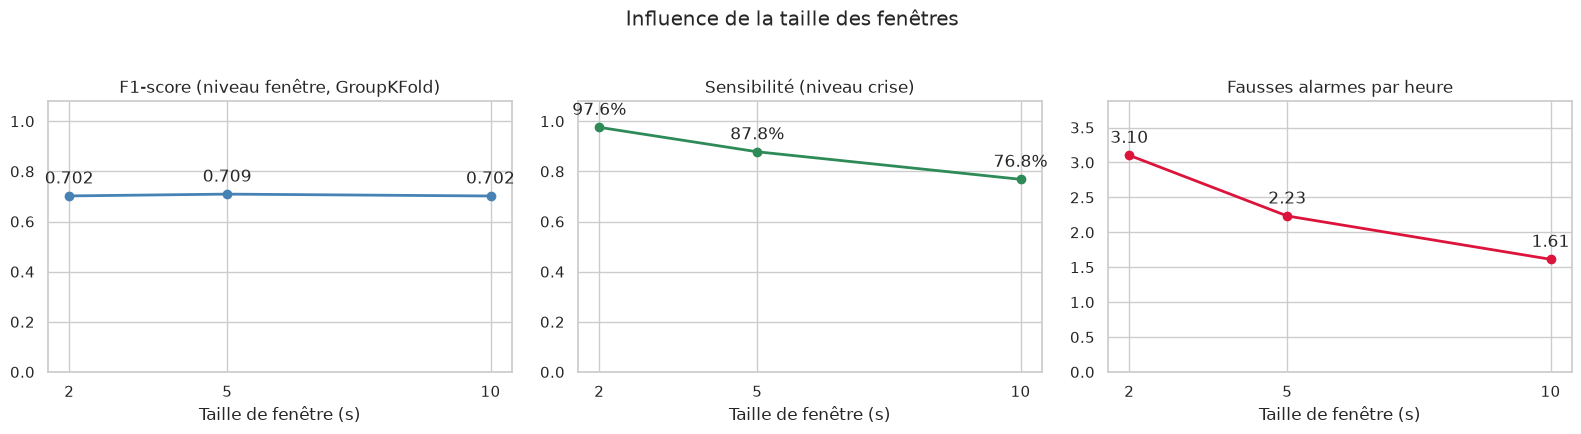

In [48]:
# Une figure : F1 (fenêtres), sensibilité (crises) et fausses alarmes par heure selon la taille de fenêtre
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
courbes = [("F1-score", "F1-score (niveau fenêtre, GroupKFold)", "steelblue", "{:.3f}"),
           ("Sensibilité crises", "Sensibilité (niveau crise)", "seagreen", "{:.1%}"),
           ("Fausses alarmes / h", "Fausses alarmes par heure", "crimson", "{:.2f}")]
for ax, (col, titre, couleur, fmt) in zip(axes, courbes):
    vals = eval_fenetres_tab[col].values
    ax.plot(WINDOW_SIZES, vals, marker="o", color=couleur, lw=2)
    for xw, v in zip(WINDOW_SIZES, vals):
        ax.annotate(fmt.format(v), (xw, v), textcoords="offset points", xytext=(0, 9), ha="center")
    ax.set(title=titre, xlabel="Taille de fenêtre (s)", xticks=WINDOW_SIZES)
for ax in axes[:2]:
    ax.set_ylim(0, 1.08)                 # même échelle 0–1 : les petits écarts ne sont pas exagérés
axes[2].set_ylim(0, 1.25 * eval_fenetres_tab["Fausses alarmes / h"].max())
plt.suptitle("Influence de la taille des fenêtres", y=1.03)
plt.tight_layout(); plt.show()

In [49]:
print(f"Durée d'exécution de la section : {time.perf_counter() - T0_FENETRES:.0f} s")

Durée d'exécution de la section : 116 s


### Interprétation

**Moins de fenêtres, et des crises courtes qui disparaissent.** En passant de 2 s à 5 s puis 10 s, le jeu passe de 28 994 à 11 581 puis 5 779 fenêtres, et les fenêtres en crise de 1 174 à 448 puis 227. La proportion de crise reste autour de 4 % (4,05 %, 3,87 %, 3,93 %) : le déséquilibre ne change pas, c'est la quantité d'exemples qui fond. Surtout, avec la règle des 50 %, une crise plus courte que la moitié de la fenêtre n'étiquette plus rien : les 82 crises gardent au moins une fenêtre à 2 s, 81 à 5 s et seulement 72 à 10 s. Dix crises annotées durent moins de 5 s (et 37 moins de 10 s, pour une médiane de 11 s) : elles sont invisibles pour un modèle à fenêtres de 10 s.

**Au niveau fenêtre, les trois tailles se valent.** Le F1 par enregistrement ne bouge presque pas : 0,702 à 2 s, 0,709 à 5 s, 0,702 à 10 s. Derrière ce score stable, l'équilibre se déplace : la précision baisse (0,743 → 0,725 → 0,699) pendant que le rappel monte (0,665 → 0,694 → 0,705). Cette métrique seule ne permet donc pas de choisir une taille, d'autant qu'elle ne « voit » pas les crises qui n'ont plus aucune fenêtre positive.

**Au niveau crise, la différence est nette.** Avec le même post-traitement, on retrouve 80 crises sur 82 à 2 s (97,6 %), 72 à 5 s (87,8 %) et 63 à 10 s (76,8 %) : 2, 10 puis 19 crises manquées. Deux effets s'additionnent : les crises courtes n'ont plus de fenêtre positive, et le lissage médian sur 3 fenêtres efface toute fenêtre positive isolée — or 3 fenêtres couvrent 4 s à 2 s, mais 20 s à 10 s. En contrepartie, les grandes fenêtres sont plus stables : les fausses alarmes passent de 25 à 18 puis 13, soit 3,10, 2,23 et 1,61 par heure sur les 8,06 h d'enregistrement. La localisation se dégrade aussi : l'écart moyen sur le début de crise passe de 1,10 s à 1,83 s puis 3,98 s, ce qui suit le pas entre deux fenêtres (1 s, 2,5 s, 5 s).

**Conclusion.** C'est bien un compromis entre précision temporelle et stabilité : allonger la fenêtre lisse le signal et réduit les fausses alarmes, mais fait perdre les crises courtes et retarde la détection. Pour des absences, souvent brèves, et dans un contexte où une crise manquée coûte plus cher qu'une fausse alarme, **la fenêtre de 2 s reste le meilleur choix** : passer à 5 s supprime 7 fausses alarmes mais fait manquer 8 crises de plus, et 10 s en fait manquer 17 de plus. Une fenêtre plus longue ne deviendrait intéressante qu'en adaptant aussi le post-traitement (lissage et durée minimale pensés en secondes plutôt qu'en nombre de fenêtres), ce qui n'a pas été testé ici.

*Les valeurs à 2 s reprennent le pipeline du notebook : même détection par crise que la partie X (80 / 82, 25 fausses alarmes). Le F1 par enregistrement peut différer de quelques dix-millièmes de celui de la partie IX selon la version de scikit-learn utilisée.*